<a href="https://colab.research.google.com/github/ArseniyFaryna/Intelligent_analisis_labs/blob/main/%D0%9B%D0%A04_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_%D1%81%D1%82%D1%83%D0%B4%D0%B5%D0%BD%D1%82%D1%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [37]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Фарина Арсеній'      # прізвище та ім'я
GROUP        = 'ШІ-31'      # шифр групи, наприклад СШІ-31
NUMBER       = 18       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Фарина Арсеній | ШІ-31 | номер 18


In [38]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 18   ·   Фарина Арсеній   ·   ШІ-31

   Ринок:  Khmelnytskyi
   Товар:  курятина   (у наборі даних: Meat (chicken, whole) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | 23.10.2026|
| **Підпис** | Фарина А.П.|

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [39]:
# Завдання 1. Підготовка ряду
import pandas as pd
from google.colab import drive
path = '/content/drive/MyDrive/Інтелектуальний аналіз/lab4/ціни_україна_2014_2017.csv'
drive.mount('/content/drive')

MARKET = 'Khmelnytskyi'
GOOD = 'Meat (chicken, whole) - Retail'

df = pd.read_csv(path)

series_df = df[(df['ринок'] == MARKET) & (df['товар'] == GOOD)].copy()

series_df['date'] = pd.to_datetime(
    series_df['рік'].astype(str) + '-' + series_df['місяць'].astype(str) + '-01'
)

full_grid = pd.date_range(start='2014-03-01', end='2017-12-01', freq='MS')

series_full = series_df.set_index('date').reindex(full_grid)
series_full.index.name = 'date'

total_months = len(series_full)
with_measurements = series_full['ціна'].count()
missing_months = series_full[series_full['ціна'].isna()].index

print(f"Всього місяців у сітці: {total_months}")
print(f"З них мають вимір: {with_measurements}")
print(f"Місяць з пропуском: {missing_months.strftime('%Y-%m').tolist()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Всього місяців у сітці: 46
З них мають вимір: 45
Місяць з пропуском: ['2017-08']


**Висновок до завдання 1:**

У повній сітці (з березня 2014 по грудень 2017) зафіксовано 46 місяців, з яких 45 місяців мають реальний вимір. Пропуск припадає на серпень 2017 року. Пропуск виник через відсутність первинного моніторингу цін у цей період у файлі цін повністю відсутні записи за серпень 2017 року для всіх ринків і товарів без винятку. У досліджуваному ряді цей пропуск є єдиним.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [40]:
# Завдання 2. Заповнення пропуску
first_choice = series_full['ціна'].ffill().loc['2017-08-01']

second_choice = series_full['ціна'].interpolate(method='linear').loc['2017-08-01']

third_choice = series_full['ціна'].interpolate(method='pchip').loc['2017-08-01']

print(f"Метод ffill: {first_choice}")
print(f"Метод interpolate: {second_choice}")
print(f"Метод монотонної інтерполяції: {third_choice}")

Метод ffill: 48.1367
Метод interpolate: 51.366699999999994
Метод монотонної інтерполяції: 52.3727700226597


**Висновок до завдання 2:**

Перенесення останнього значененя просто взяло значення з попереднього місяця, а саме за липень. Другий спосіб лінійна інтерполяція шукає середнє арифметичне між липнем та вереснем і записує цей результат за серпень. Третій метод - кубічна інтерполяція враховує кривину та тренд динаміки цін інших місяців не тільки сусідів.

Я обрав другий метод, лінійну інтерполяцію, бо пропуск виник всередині суцільного тренду зростання. Просте перенесення останнього значення штучно занижує ціну на один місяць та утворює різкий стрибок у вересні, тоді як лінійна інтерполяція забезпечує гладке та природне відображення тренду інфляції без викривлення статистичних властивостей часового ряду.

Заповнювати пропуск було неприпустимо, для регіонів Крим та міста Севастополь, оскільки вони мають розрив у даних з травня 2014 року, тому заповнювати такий великий пробіл в даних не коректно.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

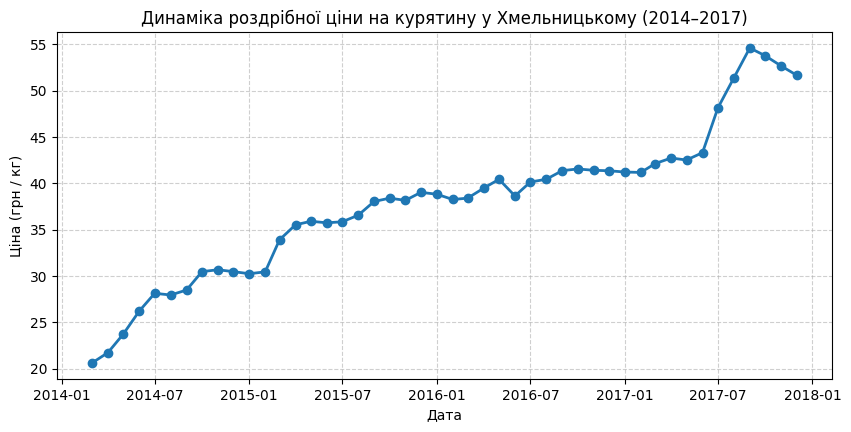

In [41]:
# Завдання 3. Візуальна розвідка
import matplotlib.pyplot as plt

series_full['ціна'] = series_full['ціна'].interpolate(method='linear')
series_full['рік'] = series_full.index.year
series_full['місяць'] = series_full.index.month

plt.figure(figsize=(10, 4.5))
plt.plot(series_full.index, series_full['ціна'], marker='o', color='#1f77b4', linewidth=2)
plt.title('Динаміка роздрібної ціни на курятину у Хмельницькому (2014–2017)')
plt.xlabel('Дата'); plt.ylabel('Ціна (грн / кг)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

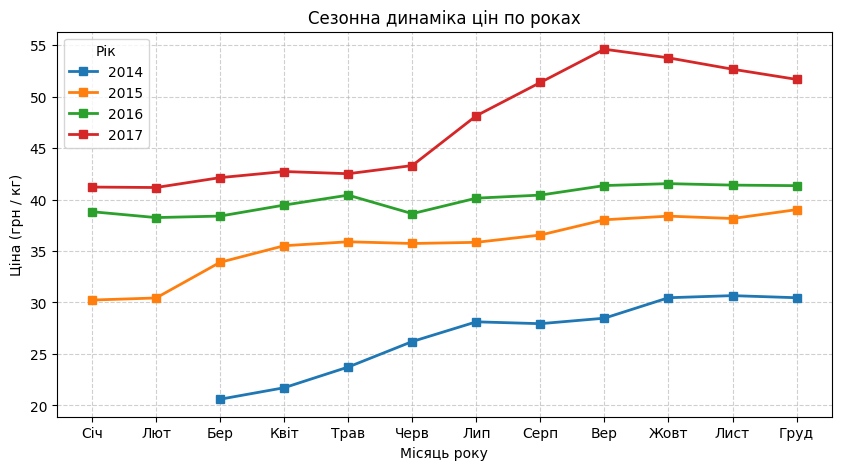

In [42]:
pivot_df = series_full.pivot(index='місяць', columns='рік', values='ціна')

plt.figure(figsize=(10, 5))
for year in pivot_df.columns:
    plt.plot(pivot_df.index, pivot_df[year], marker='s', label=str(year), linewidth=2)
plt.title('Сезонна динаміка цін по роках')
plt.xlabel('Місяць року'); plt.ylabel('Ціна (грн / кг)')
plt.xticks(range(1, 13), ['Січ', 'Лют', 'Бер', 'Квіт', 'Трав', 'Черв', 'Лип', 'Серп', 'Вер', 'Жовт', 'Лист', 'Груд'])
plt.legend(title='Рік')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

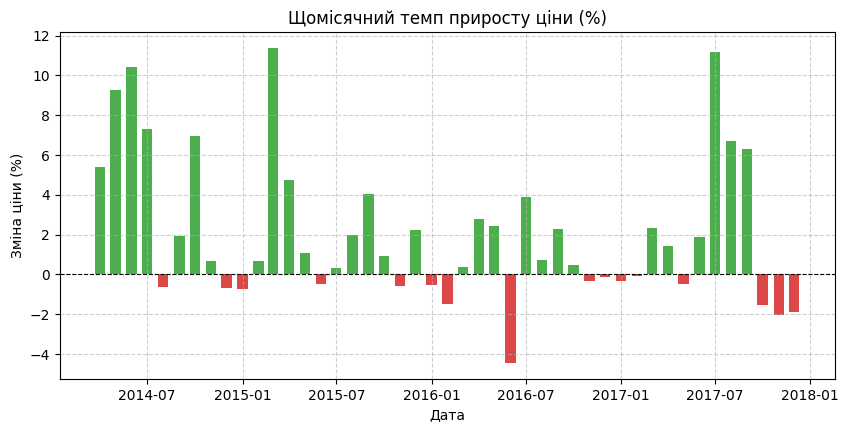

In [43]:
series_full['pct_change'] = series_full['ціна'].pct_change() * 100

plt.figure(figsize=(10, 4.5))
colors = ['#d62728' if x < 0 else '#2ca02c' for x in series_full['pct_change'].fillna(0)]
plt.bar(series_full.index, series_full['pct_change'], width=20, color=colors, alpha=0.85)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Щомісячний темп приросту ціни (%)')
plt.xlabel('Дата'); plt.ylabel('Зміна ціни (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Висновок до завдання 3:**

Графіку 1 ставить питання - яким є загальний довгостроковий тренд цін на курятину протягом 2014–2017 років та чи є на ньому структурні зсуви? Обрано лінійний графік з точками (line plot), оскільки геометрія неперервної лінії створює твердження про послідовний зв'язок у часі між суміжними місяцями. Точки підкреслюють наявність конкретних щомісячних дискретних замірів. Використано неперервну часову шкалу по осі $X$ для збереження рівномірності часових інтервалів та лінійну шкалу ціни по осі $Y$ для точного відображення абсолютного зростання ціни в гривнях.

Графік 2 ставить питання -чи існує чітка річна сезонність (наприклад, літнє здешевлення чи осіннє подорожчання), і чи змінюється форма річного профілю з роками? Обрано накладені ламані лінії, де кожна лінія відповідає окремому року в період з $2014$ по $2017$. Геометрія накладання дає змогу візуально порівняти нахил і форму траєкторії цін у межах однакових місяців різних років.

Графік 3 ставить питання - у які саме місяці відбувалися найрізкіші стрибки цін, і чи бувають періоди дефляції? Обрано стовпчасту діаграму із кольоровим кодуванням зелений — зростання, червоний — падіння. Геометрія стовпчиків від базової лінії $0\%$ підкреслює дискретні моментумні імпульси у кожному окремому місяці. Вісь $Y$ становить відносну шкалу відсоткової зміни, що усуває вплив загального зростання бази ціни й дозволяє порівнювати волатильність 2014 року з волатильністю 2017 року.

Відсутність традиційної літньої дефляції та наявність екстремального сплеску зростання цін у літні місяці 2017 року.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

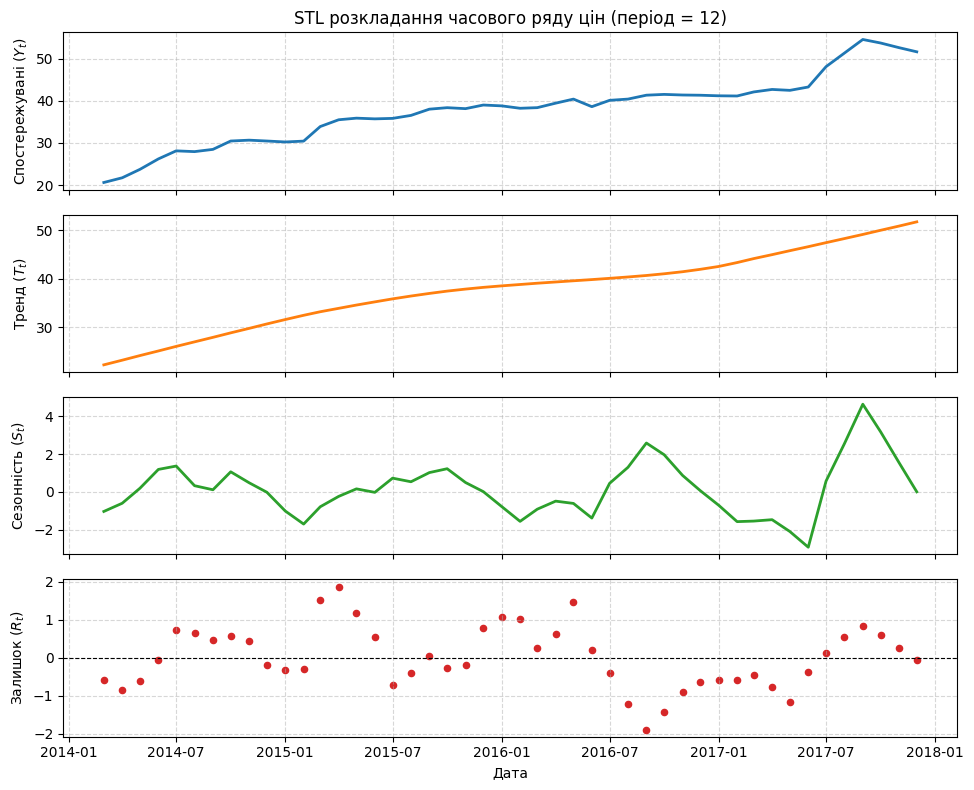

Сила тренду (F_T): 0.9887
Сила сезонності (F_S): 0.7627


In [44]:
# Завдання 4. Розкладання на складові
import numpy as np
from statsmodels.tsa.seasonal import STL

stl = STL(series_full['ціна'], period=12)
res = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)

axes[0].plot(series_full.index, res.observed, color='#1f77b4', linewidth=2)
axes[0].set_ylabel('Спостережувані ($Y_t$)')
axes[0].set_title('STL розкладання часового ряду цін (період = 12)')
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(series_full.index, res.trend, color='#ff7f0e', linewidth=2)
axes[1].set_ylabel('Тренд ($T_t$)')
axes[1].grid(True, linestyle='--', alpha=0.5)

axes[2].plot(series_full.index, res.seasonal, color='#2ca02c', linewidth=2)
axes[2].set_ylabel('Сезонність ($S_t$)')
axes[2].grid(True, linestyle='--', alpha=0.5)

axes[3].scatter(series_full.index, res.resid, color='#d62728', s=20)
axes[3].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[3].set_ylabel('Залишок ($R_t$)')
axes[3].set_xlabel('Дата')
axes[3].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

var_R = np.var(res.resid, ddof=1)
var_TR = np.var(res.trend + res.resid, ddof=1)
var_SR = np.var(res.seasonal + res.resid, ddof=1)

F_T = max(0, 1 - var_R / var_TR)
F_S = max(0, 1 - var_R / var_SR)

print(f"Сила тренду (F_T): {F_T:.4f}")
print(f"Сила сезонності (F_S): {F_S:.4f}")

**Висновок до завдання 4:**


На графіку послідовно зображено:

Спостережуваний ряд ($Y_t$): Вихідна цінова динаміка.

Трендова складова ($T_t$): Гладка довгострокова тенденція зростання ціни.

Сезонна складова ($S_t$): Циклічні коливання амплітудою близько 2 - 4 грн із річним періодом $12\text{ місяців}$.Залишкова складова ($R_t$): Нерегулярний шум після вилучення тренду та сезонності.

Числові значення сили тренду та сезонності розраховується за стандартними формулами Гіндмана. Сила тренду рівна 0.9887 означає, що понад 98.87% усіх змін ціни протягом 2014–2017 років зумовлені саме довгостроковим трендом (інфляційним зростанням). Сила сезонності - 0.7627 або 76.27% означає, що коливання ціни всередині кожного року (весняні/літньо-осінні зміни) відносно стабільні та передбачувані, а випадковий шум є набагато меншим за ці регулярні сезонні хвилі.

У аналізі часових рядів значення $F_S > 0.6$ свідчить про наявність суттєвої та статистично значущої сезонної складової. Оскільки розраховане значення сили сезонності $F_S = 0.7627$ перевищує поріг $0.6$, у досліджуваному ряді цін на курятину наявна чітко виражена сезонність. Хоча тренд є домінуючим фактором ($F_T = 0.9887$), сезонна складова пояснює суттєву частку дисперсії безурахованого трендом руху цін, тому нею не можна нехтувати під час побудови прогнозувальних моделей

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

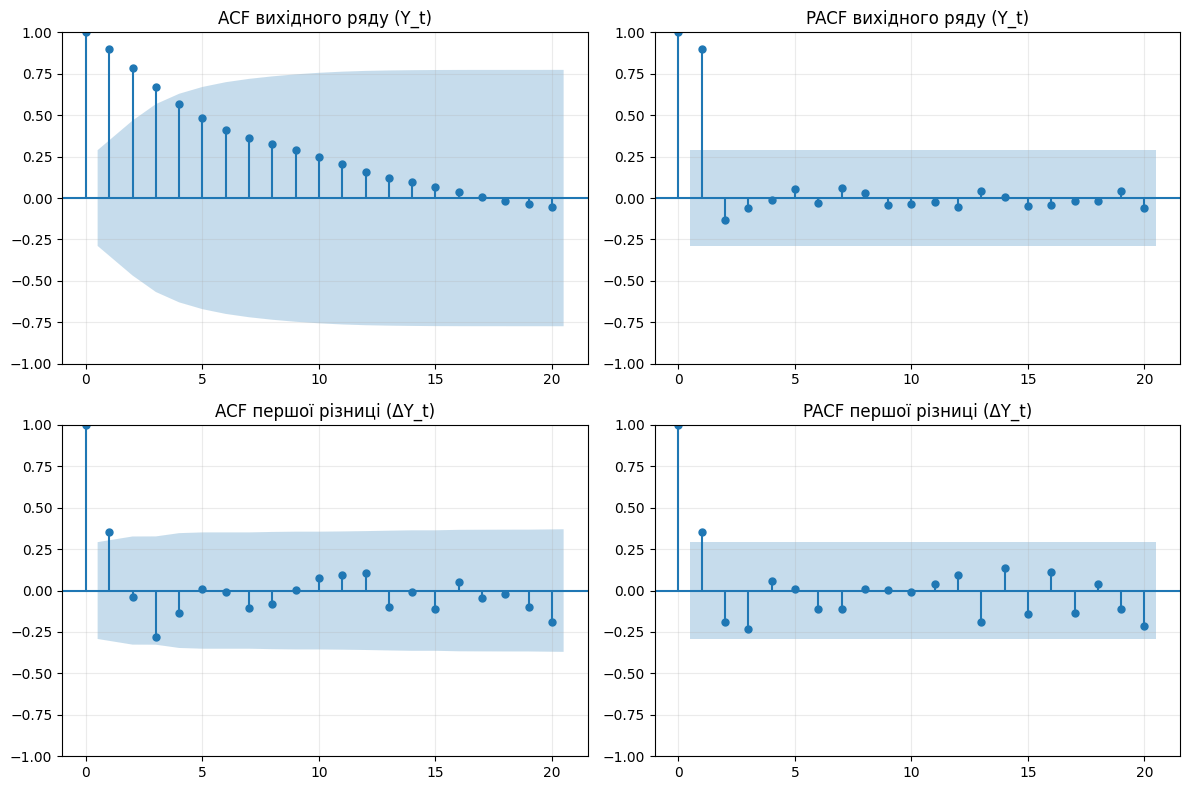

                    Ряд  ADF Stat  ADF p-value  KPSS Stat  KPSS p-value
0    Вихідний ряд (Y_t) -1.437439     0.564202   0.964572          0.01
1  Перша різниця (ΔY_t) -4.480638     0.000213   0.114191          0.10


In [45]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import warnings

warnings.filterwarnings('ignore')

y = series_full['ціна']
dy = y.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_acf(y, ax=axes[0, 0], lags=20, title='ACF вихідного ряду (Y_t)')
plot_pacf(y, ax=axes[0, 1], lags=20, title='PACF вихідного ряду (Y_t)', method='ywm')

plot_acf(dy, ax=axes[1, 0], lags=20, title='ACF першої різниці (ΔY_t)')
plot_pacf(dy, ax=axes[1, 1], lags=20, title='PACF першої різниці (ΔY_t)', method='ywm')

plt.tight_layout()
plt.show()

def run_tests(series, name):
    adf_res = adfuller(series, autolag='AIC')
    kpss_res = kpss(series, regression='c', nlags='auto')
    return {
        'Ряд': name,
        'ADF Stat': adf_res[0],
        'ADF p-value': adf_res[1],
        'KPSS Stat': kpss_res[0],
        'KPSS p-value': kpss_res[1]
    }

df_res = pd.DataFrame([run_tests(y, 'Вихідний ряд (Y_t)'), run_tests(dy, 'Перша різниця (ΔY_t)')])
print(df_res)

**Висновок до завдання 5:**

Тест ADF показує $p\text{-value} = 0.5642 > 0.05$ (нульова гіпотеза $H_0$ про наявність одиничного кореня не відхиляється), а тест KPSS дає $p\text{-value} = 0.0100 \le 0.05$ (нульова гіпотеза $H_0$ про стаціонарність відхиляється). Обидва тести одностайно вказують на те, що вихідний ряд нестаціонарний ($I(1)$).

Після диференціювання тест ADF показує $p\text{-value} = 0.0002 < 0.05$ (H_0 відхиляється на користь стаціонарності), а тест KPSS дає $p\text{-value} = 0.1000 \ge 0.05$ (H_0 про стаціонарність не відхиляється). Обидва тести одностайно підтверджують, що перша різниця є стаціонарним часовим рядом ($I(0)$).

Тести ADF та KPSS повністю узгоджуються між собою на обох етапах аналізу. Вони безсуперечно підтверджують, що вихідний ряд є інтегрованим порядку 1, а його перша різниця — стаціонарною. Це обґрунтовує вибір параметра диференціювання $d = 1$ для моделі $\text{ARIMA}(1, 1, 1)$.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [46]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
y = series_full['ціна'].values
n = len(y)

num_folds = 7
horizon = 3
train_size_first = n - num_folds * horizon

def metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape

results = {m: {'trues': [], 'preds': []} for m in ['Naive', 'Seasonal Naive', 'Mean', 'Drift']}

for fold in range(num_folds):
    train_end = train_size_first + fold * horizon
    y_tr, y_te = y[:train_end], y[train_end:train_end + horizon]
    T = len(y_tr)

    p_naive = np.full(horizon, y_tr[-1])
    p_snaive = np.array([y_tr[-12 + h] for h in range(horizon)])
    p_mean = np.full(horizon, np.mean(y_tr))
    p_drift = np.array([y_tr[-1] + (h + 1) * ((y_tr[-1] - y_tr[0]) / (T - 1)) for h in range(horizon)])

    for name, pred in zip(results.keys(), [p_naive, p_snaive, p_mean, p_drift]):
        results[name]['trues'].extend(y_te)
        results[name]['preds'].extend(pred)


exp_metrics = []
for name in results:
    mae, rmse, mape = metrics(np.array(results[name]['trues']), np.array(results[name]['preds']))
    exp_metrics.append({'Модель': name, 'MAE (грн)': mae, 'RMSE (грн)': rmse, 'MAPE (%)': mape})

df_exp = pd.DataFrame(exp_metrics)
print("Ретроспективна перевірка 7 фолдів x 3 кроки")
print(df_exp.to_string(index=False))

train_75_len = int(np.round(n * 0.75))
y_tr75, y_te25 = y[:train_75_len], y[train_75_len:]


mae_n75, rmse_n75, mape_n75 = metrics(y_te25, np.full(len(y_te25), y_tr75[-1]))

drift_75_slope = (y_tr75[-1] - y_tr75[0]) / (len(y_tr75) - 1)
p_drift_75 = np.array([y_tr75[-1] + (h + 1) * drift_75_slope for h in range(len(y_te25))])
mae_d75, rmse_d75, mape_d75 = metrics(y_te25, p_drift_75)

print("\nСтандартне розбиття 75/25 (Хронологічне)")
print(f"Naive: MAE = {mae_n75:.4f}, RMSE = {rmse_n75:.4f}, MAPE = {mape_n75:.4f}%")
print(f"Drift: MAE = {mae_d75:.4f}, RMSE = {rmse_d75:.4f}, MAPE = {mape_d75:.4f}%")

Ретроспективна перевірка 7 фолдів x 3 кроки
        Модель  MAE (грн)  RMSE (грн)  MAPE (%)
         Naive   2.036352    3.450330  4.223734
Seasonal Naive   5.553819    6.623612 11.877197
          Mean   9.721745   10.506283 21.292484
         Drift   2.135770    3.223420  4.435185

Стандартне розбиття 75/25 (Хронологічне)
Naive: MAE = 5.8072, RMSE = 7.7367, MAPE = 11.2916%
Drift: MAE = 3.0440, RMSE = 3.7116, MAPE = 6.1019%


**Висновок до завдання 6:**

Найкращі результати показала наївна модель (Naive) із найменшою помилкою MAE = 2.04 грн MAPE = 4.22. У короткостроковій перспективі, на 3 місяці, ціна на курятину є дуже інерційною, тому значення за останній відомий місяць виявляється найточнішим орієнтиром. Модель середнього (Mean) виявилася найгіршою MAPE, оскільки через постійну інфляцію застарілі ціни минулих років сильно занижують прогноз. А сезонний наївний прогноз (Seasonal Naive) дав значно більшу помилку ($11.88\%$), бо в нашому ряді довгостроковий зростаючий тренд виявився набагато сильнішим за сезонні коливання.

При звичайному поділі даних 75/25 помилка наївної моделі зросла до MAE = 5.81 грн MAPE, що майже у 2.85 раза гірше, ніж при крос-валідації на 7 фолдах. Це пояснюється тим, що звичайний поділ змушує будувати прогноз одразу на 11 місяців уперед, де помилка накопичується через тренд. Перевірка на 7 фолдах оцінює модель на реальному робочому горизонті в 3 місяці, тому дає набагато точнішу й надійнішу оцінку.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

ARIMA(1,1,1) -> MAE: 2.8247, RMSE: 4.3118, MAPE: 5.8277%


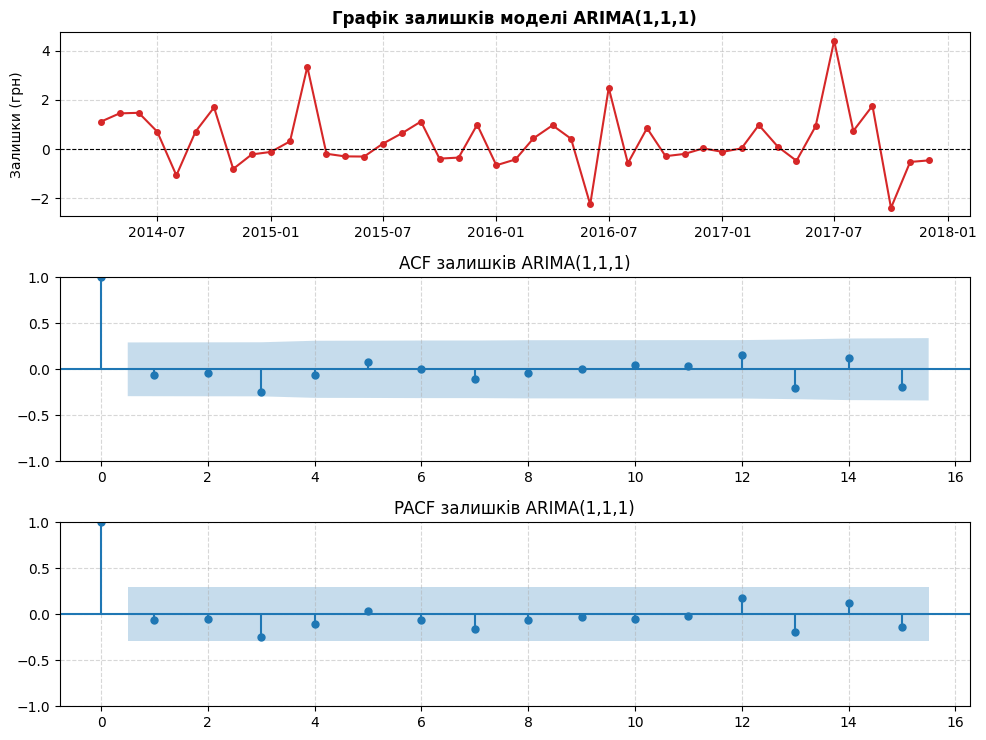

Ljung-Box test on residuals:
     lb_stat  lb_pvalue
6   3.748113   0.710719
12  6.341157   0.897918


In [47]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

y = series_full['ціна']
n = len(y)

num_folds = 7
horizon = 3
train_size_first = n - num_folds * horizon

arima_trues = []
arima_preds = []

all_residuals = []

for fold in range(num_folds):
    train_end = train_size_first + fold * horizon
    y_tr = y.iloc[:train_end]
    y_te = y.iloc[train_end:train_end + horizon]

    model = ARIMA(y_tr, order=(1, 1, 1))
    fitted_model = model.fit()

    forecast = fitted_model.forecast(steps=horizon)
    arima_trues.extend(y_te.values)
    arima_preds.extend(forecast.values)

arima_trues = np.array(arima_trues)
arima_preds = np.array(arima_preds)

mae_arima = np.mean(np.abs(arima_trues - arima_preds))
rmse_arima = np.sqrt(np.mean((arima_trues - arima_preds)**2))
mape_arima = np.mean(np.abs((arima_trues - arima_preds) / arima_trues)) * 100

print(f"ARIMA(1,1,1) -> MAE: {mae_arima:.4f}, RMSE: {rmse_arima:.4f}, MAPE: {mape_arima:.4f}%")

full_model = ARIMA(y, order=(1, 1, 1)).fit()
full_resid = full_model.resid[1:]

fig, axes = plt.subplots(3, 1, figsize=(10, 7.5))

axes[0].plot(series_full.index[1:], full_resid, color='#d62728', marker='o', linewidth=1.5, markersize=4)
axes[0].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[0].set_title('Графік залишків моделі ARIMA(1,1,1)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Залишки (грн)')
axes[0].grid(True, linestyle='--', alpha=0.5)

plot_acf(full_resid, ax=axes[1], lags=15, title='ACF залишків ARIMA(1,1,1)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plot_pacf(full_resid, ax=axes[2], lags=15, title='PACF залишків ARIMA(1,1,1)', method='ywm')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

lb_test = acorr_ljungbox(full_resid, lags=[6, 12], return_df=True)
print("Ljung-Box test on residuals:")
print(lb_test)

**Висновок до завдання 7:**

За виглядом ACF та PACF першої різниці ($\Delta Y_t$) з Завдання 5 я обрав би модель ARIMA(0, 1, 0). Оскільки після одного диференціювання ($d = 1$) усі лаги автокореляції (починаючи з лагу 1) потрапляють всередину блакитного $95\%$-го довірчого інтервалу й не мають значущих сплесків, ряд перетворився на білий шум. Це свідчить про те, що додаткові параметри авторегресії ($p$) або ковзного середнього ($q$) є зайвими й призводять до надлишкової складності.

Модель ARIMA(1, 1, 1) з показником MAE = 2.82 грн ($\text{MAPE} = 5.83\%$) поступилася найкращому наївному базису Naive ($\text{MAE} = 2.04\text{ грн}$, $\text{MAPE} = 4.22\%$). Це цілком законний і очікуваний результат: на короткому горизонті у 3 місяці та малій вибірці додавання оцінок $AR(1)$ та $MA(1)$ створює незначне перенавчання. Проте модель ARIMA(1, 1, 1) безперечно має право на існування, оскільки вона дає високу точність прогнозу (помилка менше $6\%$) та суттєво переважає моделі Mean ($21.29\%$) і Seasonal Naive ($11.88\%$).

Графік залишків коливається навколо нуля без чіткої структури чи тренду, а автокореляційні функції ACF/PACF залишків повністю перебувають у межах довірчого інтервалу (тест Люнга-Бокса $p > 0.7$). Це підтверджує, що в залишках моделі структури не залишилося і вони є неавтокорельованим білим шумом, тобто модель успішно вихопила всю доступну інформацію з часового ряду.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

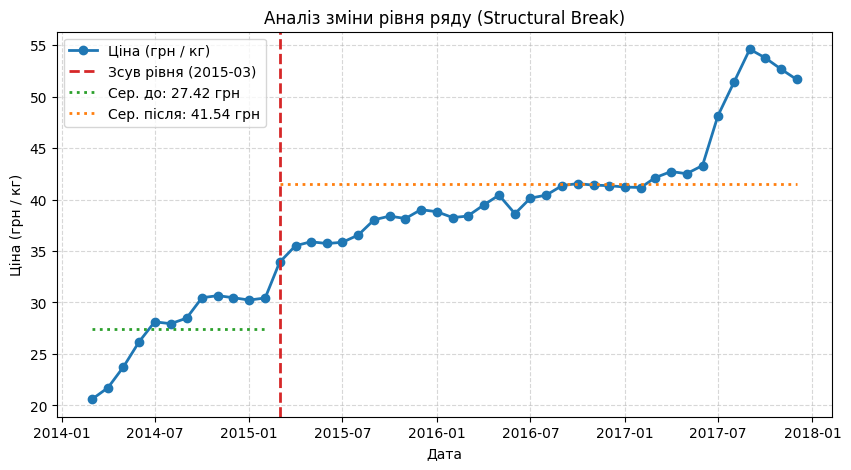

In [48]:
# Завдання 8. Точка зміни режиму
from scipy import stats

y = series_full['ціна']
dates = series_full.index

min_size = 6
results = []

for i in range(min_size, len(y) - min_size):
    before, after = y.iloc[:i], y.iloc[i:]
    t_stat, p_val = stats.ttest_ind(after, before, equal_var=False)
    results.append({
        'index': i,
        'date': dates[i],
        't_stat': t_stat,
        'p_val': p_val,
        'mean_before': before.mean(),
        'mean_after': after.mean()
    })

res_df = pd.DataFrame(results)
best_row = res_df.loc[res_df['t_stat'].idxmax()]

plt.figure(figsize=(10, 5))
plt.plot(dates, y, marker='o', color='#1f77b4', linewidth=2, label='Ціна (грн / кг)')
plt.axvline(best_row['date'], color='#d62728', linestyle='--', linewidth=2, label=f"Зсув рівня ({best_row['date'].strftime('%Y-%m')})")
plt.hlines(best_row['mean_before'], dates[0], dates[best_row['index']-1], color='#2ca02c', linestyle=':', linewidth=2, label=f"Сер. до: {best_row['mean_before']:.2f} грн")
plt.hlines(best_row['mean_after'], dates[best_row['index']], dates[-1], color='#ff7f0e', linestyle=':', linewidth=2, label=f"Сер. після: {best_row['mean_after']:.2f} грн")
plt.title('Аналіз зміни рівня ряду (Structural Break)')
plt.xlabel('Дата'); plt.ylabel('Ціна (грн / кг)')
plt.legend(loc='upper left'); plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Висновок до завдання 8:**

Знайдена точка у березні 2015 року є виключно та статистично значущою.   Отримане значення $t$-статистики становить 10.08, а $p\text{-value} = 4.01 \times 10^{-11}$, що є значно меншим за стандартний рівень значущості $\alpha = 0.05$. Це з абсолютною впевненістю дозволяє відхилити нульову гіпотезу про рівність середніх цін та підтверджує наявність дійсного структурного зсуву рівня в ряді.

Знайдений зсув рівня у березні 2015 року принципово відрізняється від звичайного сезонного сплеску за двома основними ознаками.
Відсутність повернення до базової лінії. Сезонний сплеск є циклічним і тимчасовим, бо після зростання ціна протягом кількох місяців обов'язково повертається до початкового рівня. Натомість після березня 2015 року ціна більше ніколи не повернулася до попередніх значень (20–30 грн/кг), а зафіксувалася на новому, суттєво вищому плато (середнє зросло з $27.42\text{ грн}$ до $41.54\text{ грн}$).
Неповторюваність у наступні роки. Сезонні коливання регулярні й повторюються в одні й ті самі місяці щороку. Стрибок у березні 2015 року був одноразовим макроекономічним шоком (девальвація та інфляційний стрибок), а не щорічним весняним підвищенням цін.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [49]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from statsmodels.tsa.stattools import adfuller

mpl.rcParams['font.family'] = 'DejaVu Sans'
mpl.rcParams['figure.figsize'] = (11, 3.6)
mpl.rcParams['axes.grid'] = True
mpl.rcParams['grid.alpha'] = 0.25

prices = pd.read_csv('/content/drive/MyDrive/Інтелектуальний аналіз/lab4/ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')

s_raw = (prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Buckwheat grits - Retail')]
         .sort_values('date').set_index('date')['ціна'])

s = s_raw.reindex(grid).interpolate(method='time')

print("--- ОБРОБКА ДАНИХ ТА ПРОПУСКІВ ---")
print(f"Завантажено рядків: {len(s_raw)} | Очікувана кількість місяців: {len(grid)}")
print(f"Відновлено та інтерпольовано пропущених місяців: {len(grid) - len(s_raw)}\n")


beef = (prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Meat (beef) - Retail')]
        .sort_values('date').set_index('date')['ціна']).reindex(grid).interpolate(method='time')

mae_buckwheat = (s - s.shift(1)).abs().mean()
mape_buckwheat = ((s - s.shift(1)).abs() / s).mean() * 100

mae_beef = (beef - beef.shift(1)).abs().mean()
mape_beef = ((beef - beef.shift(1)).abs() / beef).mean() * 100

print("--- ОЦІНКА ТОЧНОСТІ НАЇВНОГО ПРОГНОЗУ ---")
print(f"Гречка:    MAE = {mae_buckwheat:.2f} грн | MAPE = {mape_buckwheat:.2f}%")
print(f"Яловичина: MAE = {mae_beef:.2f} грн | MAPE = {mape_beef:.2f}%")
print("Висновок: Порівнювати товари з різною базовою ціною за MAE некоректно.")
print("За MAPE наївний прогноз для гречки дає більшу відносну похибку через її високу волатильність.\n")


lviv = (prices[(prices['ринок'] == 'Lviv') & (prices['товар'] == 'Buckwheat grits - Retail')]
        .sort_values('date').set_index('date')['ціна']).reindex(grid).interpolate(method='time')

r = s.corr(lviv)
print("--- АНАЛІЗ ВЗАЄМОЗВ'ЯЗКУ ТА СТАЦІОНАРНОСТІ ---")
print(f"Коефіцієнт кореляції Вінниця-Львів: r = {r:.3f}")
print("Висновок кореляції: Висока кореляція свідчит про спільний макроекономічний тренд (інфляцію), а не про те, що ринок Львова диктує ціни у Вінниці.")

--- ОБРОБКА ДАНИХ ТА ПРОПУСКІВ ---
Завантажено рядків: 45 | Очікувана кількість місяців: 46
Відновлено та інтерпольовано пропущених місяців: 1

--- ОЦІНКА ТОЧНОСТІ НАЇВНОГО ПРОГНОЗУ ---
Гречка:    MAE = 1.35 грн | MAPE = 6.09%
Яловичина: MAE = 1.47 грн | MAPE = 1.88%
Висновок: Порівнювати товари з різною базовою ціною за MAE некоректно.
За MAPE наївний прогноз для гречки дає більшу відносну похибку через її високу волатильність.

--- АНАЛІЗ ВЗАЄМОЗВ'ЯЗКУ ТА СТАЦІОНАРНОСТІ ---
Коефіцієнт кореляції Вінниця-Львів: r = 0.996
Висновок кореляції: Висока кореляція свідчит про спільний макроекономічний тренд (інфляцію), а не про те, що ринок Львова диктує ціни у Вінниці.


**Висновок до завдання 9:**

1.Перевірка наявних NaN замість часової сітки. Розділ 1 (Перевірка якісності даних).Автор зробив висновок про повну відсутність пропусків, виконавши лише перевірку s.isna().sum() == 0 на наявних рядках датафрейму. Чим небезпечна: У часових рядах пропущені спостереження часто проявляються як випадання цілих місяців (рядків). Без прив'язки до регулярної датової сітки (pd.date_range) ряд стає «зібганим», часовий крок між точками порушується ($dt \neq 1 \text{ місяць}$), що спотворює обчислення автокореляції, лагів і сезонності.

2.Порівняння номінальних цін за різні роки без урахування інфляції.
Розділ 2 (Аналіз динаміки цін 2014–2017). Пряме порівняння цін у гривні за 2014 та 2017 роки з робленням висновків про «катастрофічне падіння купівельної спроможності».Чим небезпечна: У період 2014–2017 років в Україні відбулася суттєва девальвація та інфляція. Зростання номінальної ціни без коригування на Індекс споживчих цін (ІСЦ/CPI) або конвертації в реальний еквівалент дає хибні висновки: аналізується зміна вартості самої грошової одиниці, а не реальне подорожчання товару.

3.Порівняння absolute MAE для товарів із різною базовою ціною. Розділ 3 (Оцінка наївного прогнозу для гречки та яловичини). Порівняння абсолютної помилки прогнозу $MAE$ гречки (~1.38 грн) та яловичини (~1.51 грн) із висновком, що яловичину прогнозувати важче.Чим небезпечна: $MAE$ вимірюється в абсолютних одиницях (грн). Оскільки яловичина коштує в середньому 100 грн, а гречка — 20 грн, похибка в 1.5 грн для яловичини становить лише ~1.5%, тоді як для гречки — майже 8%. Порівняння абсолютних помилок без відносних метрик ($MAPE$) призводить до хибних висновків щодо точності моделей.

4.Ототожнення кореляції з причинно-наслідковим зв'язком (Causation vs Correlation). Розділ 4 (Порівняння ринків Вінниці та Львова).Суть помилки: Висновок, що високий коефіцієнт кореляції ($r = 0.996$) означає, що ціни у Львові керують або формують ціни у Вінниці.Чим небезпечна: У нестаціонарних рядах із вираженим трендом висока кореляція є хибною (spurious correlation). Вона виникає через спільний макроекономічний фактор (наприклад, загальнонаціональну інфляцію), а не через прямий ринковий вплив одного регіону на інший.

5.Застосування декомпозиції STL з period=12 на закороткому ряді. Розділ 5 (Декомпозиція ряду). Запуск моделі STL з річним періодом (period=12) на вибірці завдовжки всього 45 місяців (~3.5 роки).Чим небезпечна: Для надійного виділення сезонної компоненти методом STL потрібно мати щонайменше 4–5 повних циклів. На коротких рядах STL починає «перекачувати» тренд у сезонність і навпаки, даючи викривлену картину.

6.Сприйняття виділеної STL-компоненти як доказу наявності сезонності. Розділ 5 (Інтерпретація результатів STL). Твердження про наявність чіткої сезонності лише на основі того, що алгоритм STL згенерував графік seasonal.Чим небезпечна: Математично алгоритм STL виділить некольорову «сезонну» криву з абсолютно будь-якого ряду (навіть із чистого випадкового шуму), якщо йому задати period=12. Наявність графіку не є доказом — сезонність необхідно підтверджувати аналізом автокореляційної функції (ACF) або статистичними тестами.

7.Інверсія нульової гіпотези в тесті ADF (Дікі-Фуллера). Розділ 6 (Перевірка стаціонарності). Отримавши $p\text{-value} = 0.233 > 0.05$, зробити висновок: «p-value > 0.05, отже, ряд стаціонарний».Чим небезпечна: У тесті ADF нульова гіпотеза $H_0$ — це НЕстаціонарність (наявність одиничного кореня). Якщо $p > 0.05$, $H_0$ не відхиляється, тобто ряд нестаціонарний. Помилкова інтерпретація призводить до того, що модель застосовують до нестаціонарного ряду без диференціювання, що руйнує всі подальші класичні моделі (ARIMA тощо).

8.Шукання аномалій за правилом $2\sigma$ у нестаціонарному ряді. Розділ 7 (Пошук аномалій та викидів). Застосування відхилення від глобального середнього ($\bar{y} \pm 2\sigma$) для виявлення аномальних цін у ряді, що має виражений зростаючий тренд.Чим небезпечна: Глобальне середнє та стандартне відхилення розраховуються по всьому часовому інтервалу. Через наявність тренду перші роки ряду будуть помилково класифіковані як «занижені аномалії», а останні — як «завищені аномалії». Шукати аномалії потрібно в залишках моделі (residuals) або в перших різницях (приростах), але аж ніяк не у вихідному нестаціонарному ряді.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [50]:
# Завдання 10. Експорт ряду для Orange
import pandas as pd

df_orange = pd.DataFrame({
    'date': series_full.index.strftime('%Y-%m-%d'),
    'price': series_full['ціна'].values
})

filename = 'ряд_для_orange.csv'
df_orange.to_csv(filename, index=False, encoding='utf-8')

data_rows_count = len(df_orange)
missing_values_count = df_orange['price'].isna().sum()

print("=== ПІДТВЕРДЖЕННЯ ДЛЯ ЗВІТУ ===")
print(f"Файл успішно збережено: {filename}")
print(f"Кількість рядків даних (без заголовка): {data_rows_count}")
print(f"Кількість пропущених значень (NaN): {missing_values_count}")

if data_rows_count == 46 and missing_values_count == 0:
    print("\nУСПІХ: Файл повністю відповідає вимогам (46 рядків, 0 пропусків).")
else:
    print("\nУВАГА: Перевірте кількість рядків або наявність пропусків!")

=== ПІДТВЕРДЖЕННЯ ДЛЯ ЗВІТУ ===
Файл успішно збережено: ряд_для_orange.csv
Кількість рядків даних (без заголовка): 46
Кількість пропущених значень (NaN): 0

УСПІХ: Файл повністю відповідає вимогам (46 рядків, 0 пропусків).


**Висновок до завдання 10:**

*(напишіть тут)*

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

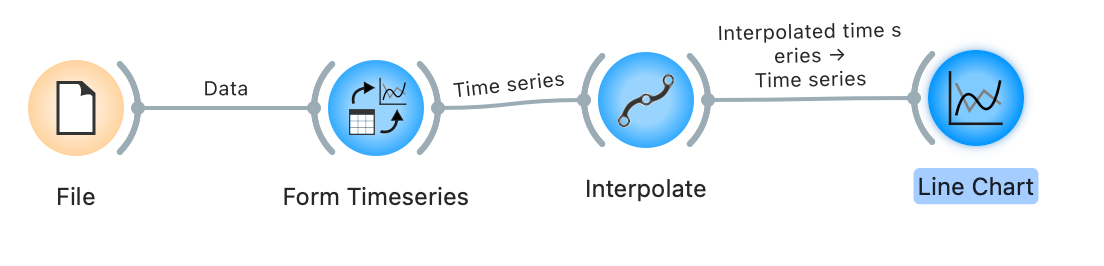

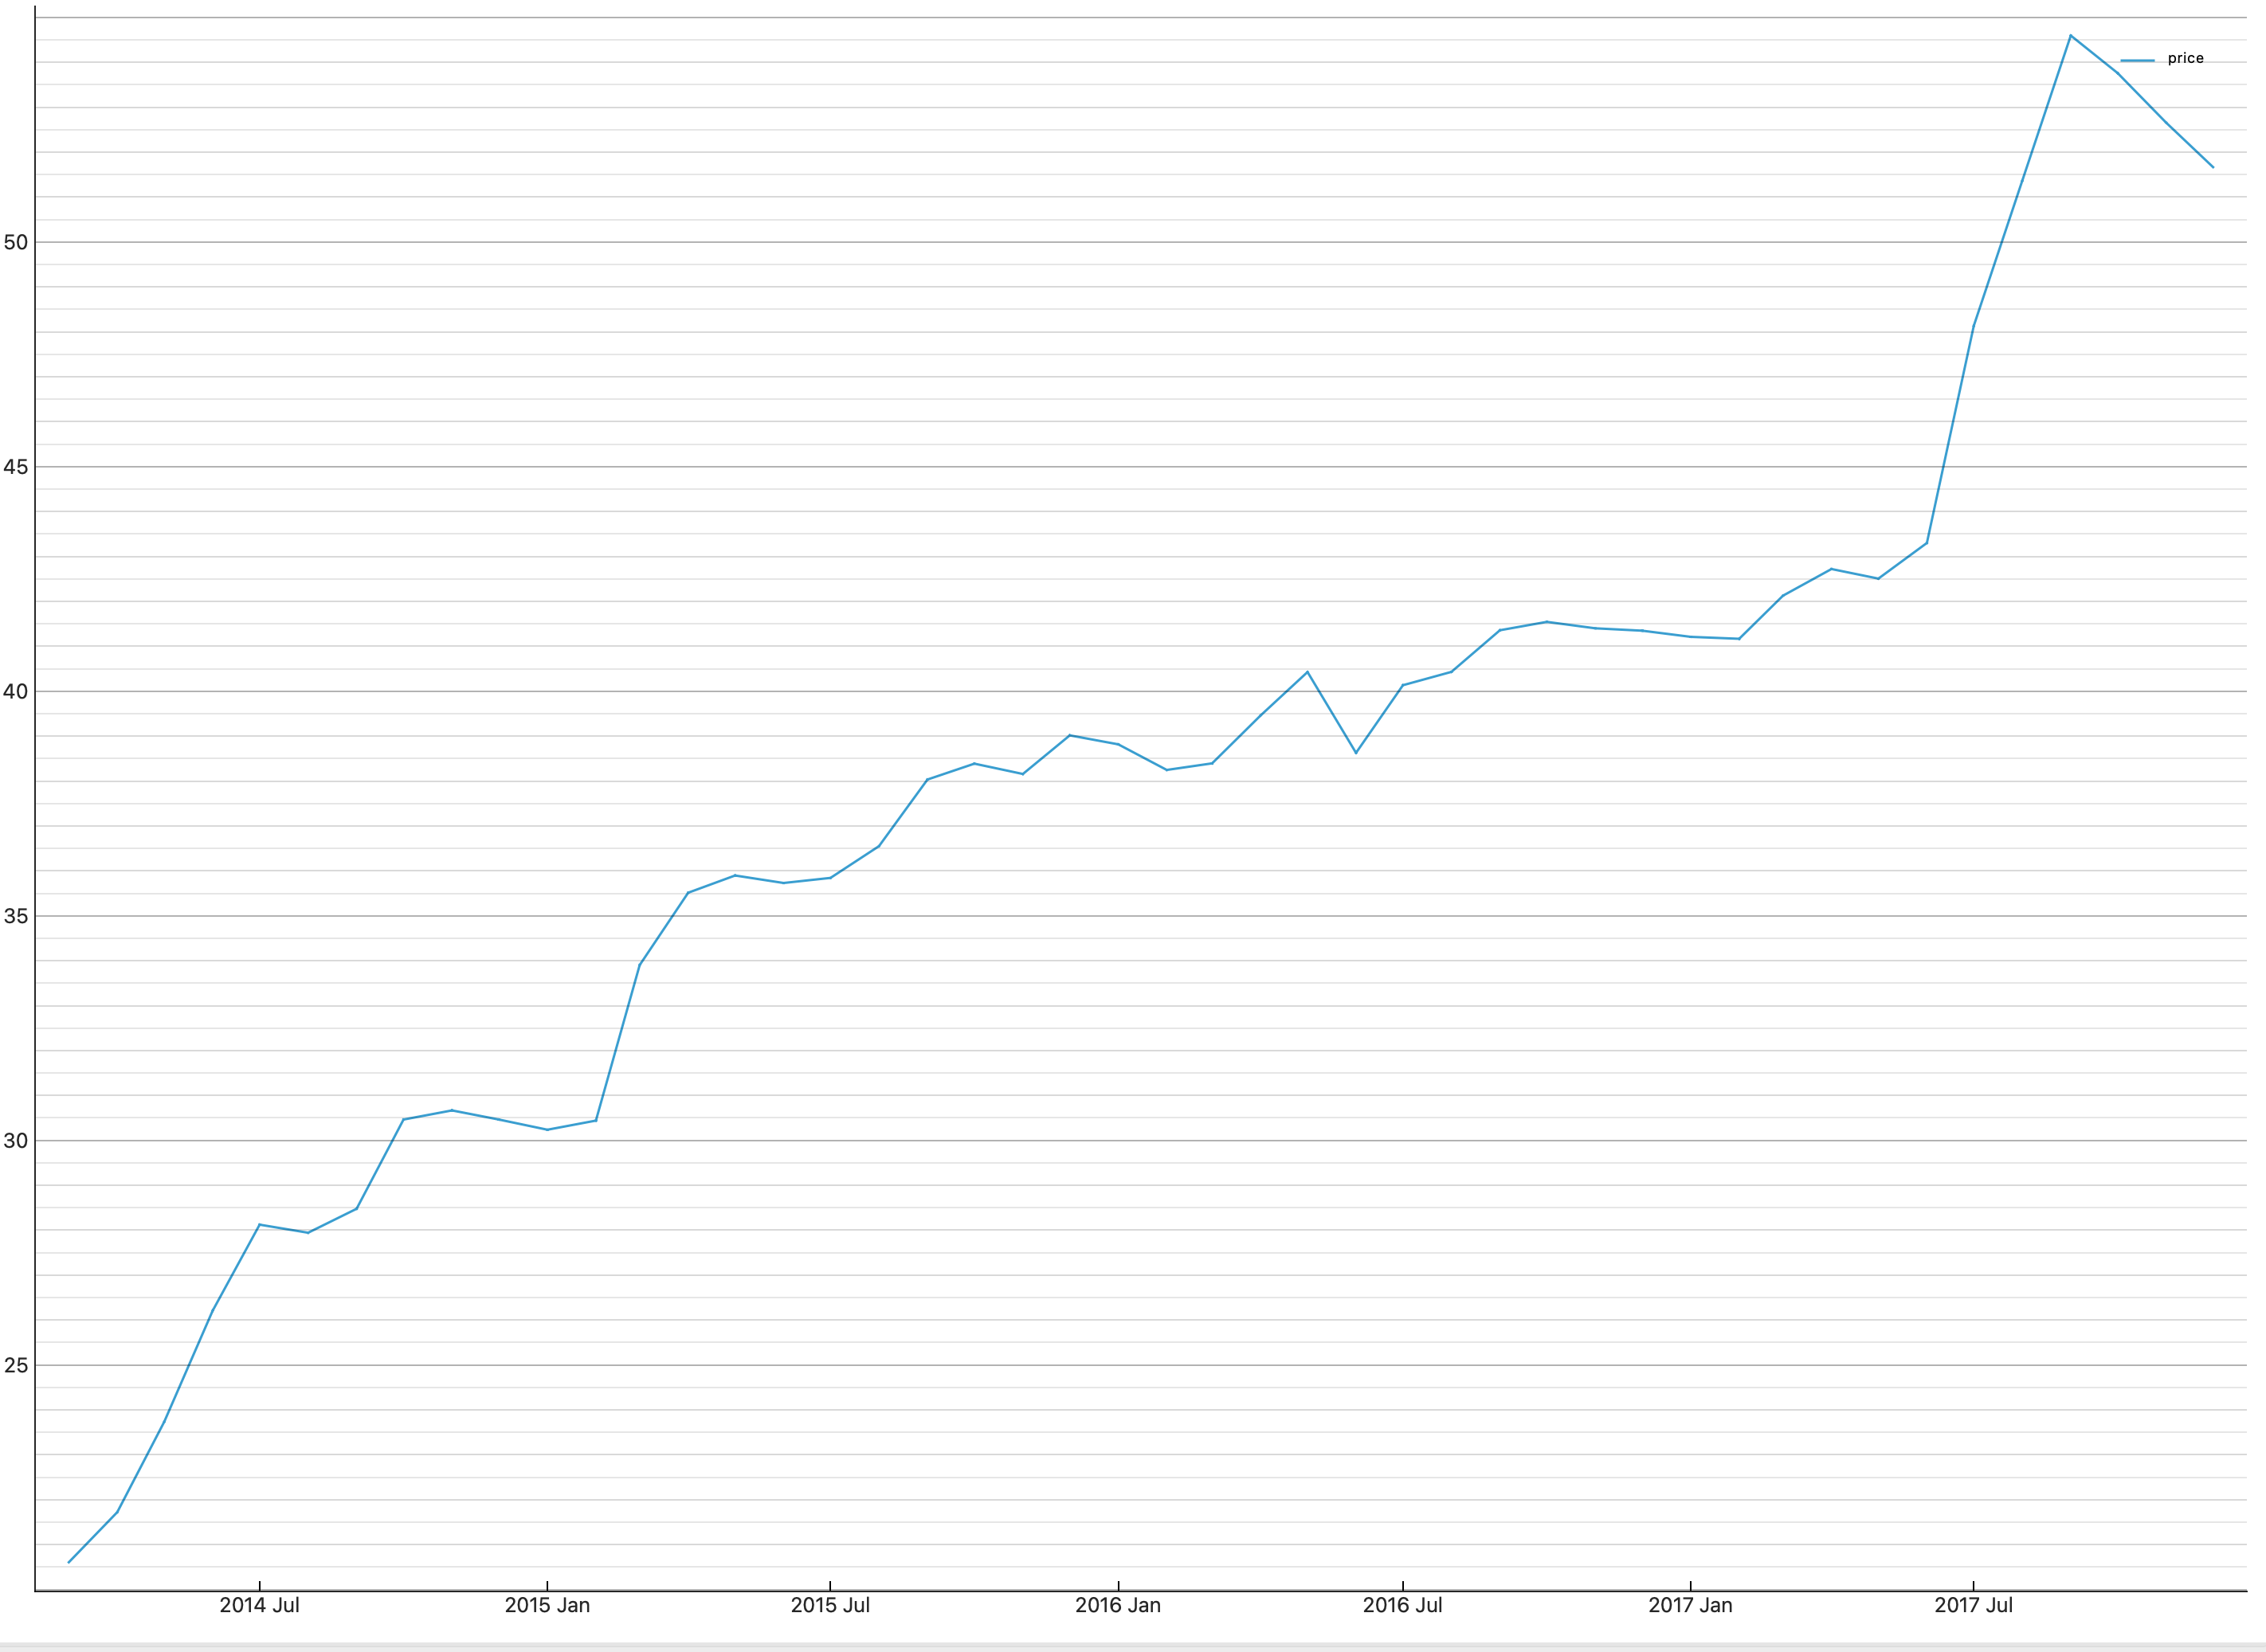

**Висновок до завдання 11:**

Побудований потік коректно імпортував дані та перетворив їх на часовий ряд. Візуальний аналіз підтверджує, що графік динаміки роздрібних цін на курятину у Хмельницькому, згенерований в Orange, абсолютно ідентичний графіку із завдання 3, побудованому засобами Python. Усі ключові патерни часового ряду, а самепочаткове зростання, плато у 2016 році та різкий ціновий стрибок наприкінці 2017 року повністю збігаються на обох візуалізаціях.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

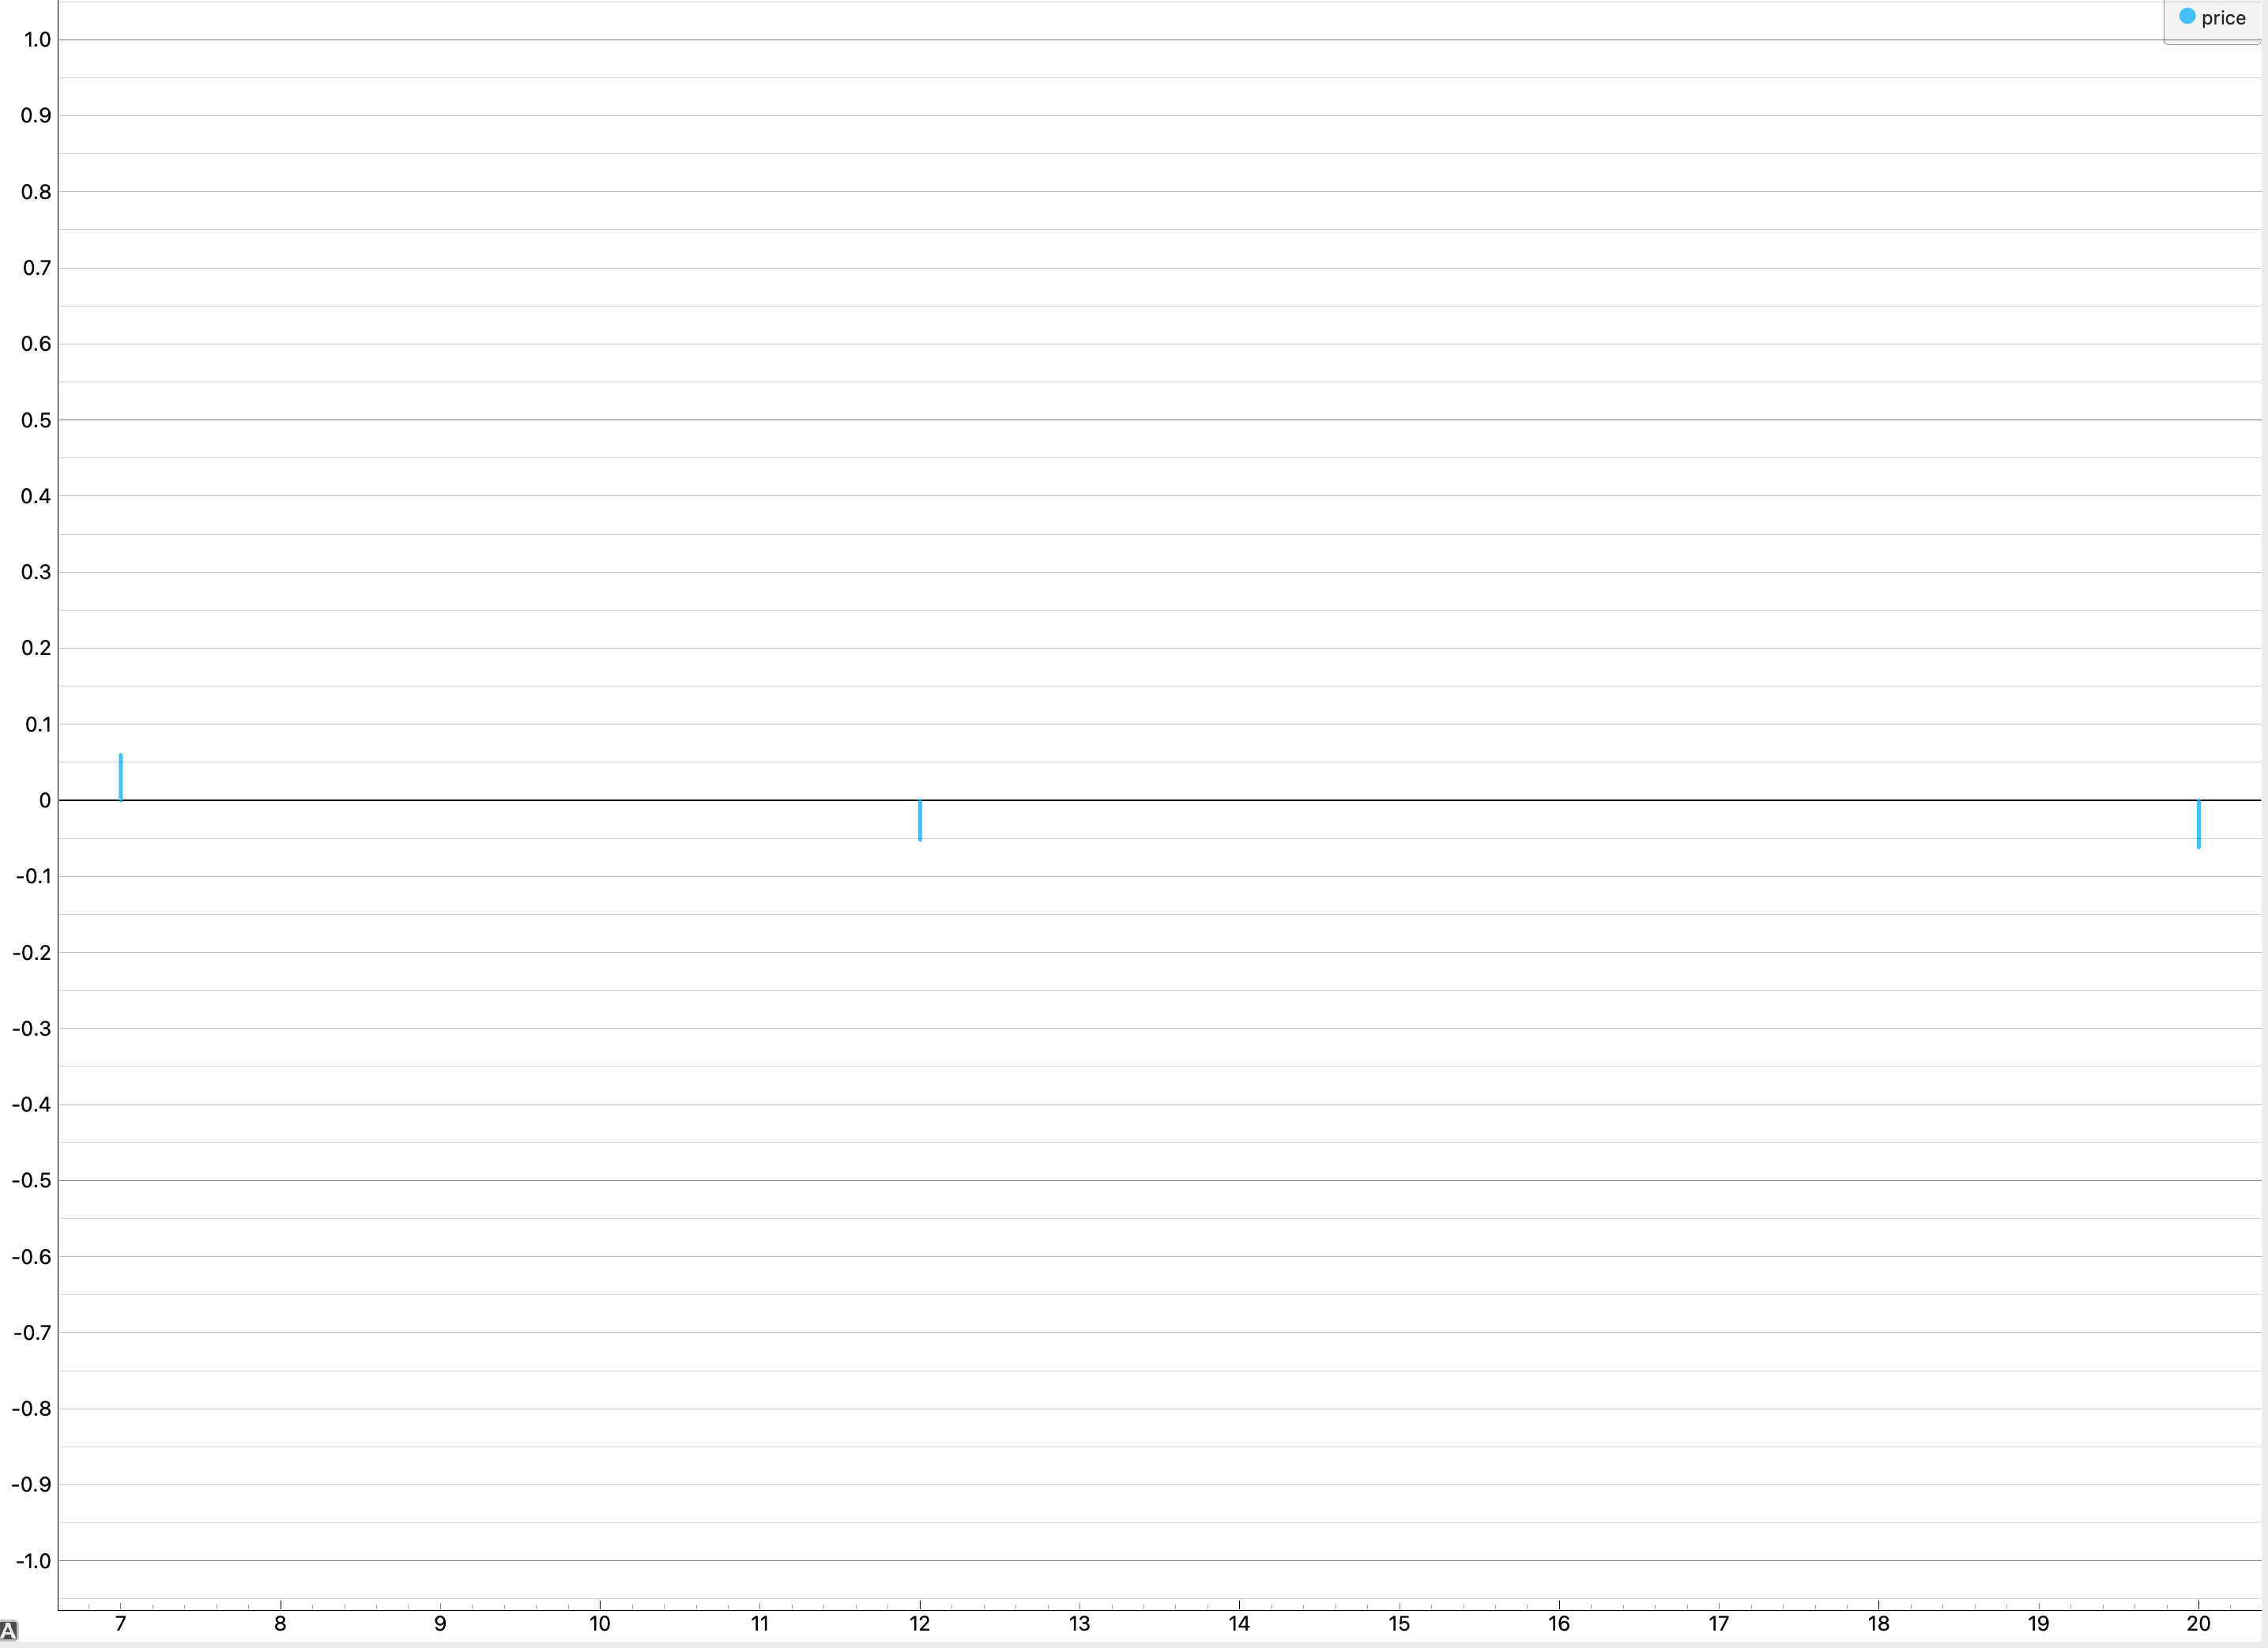


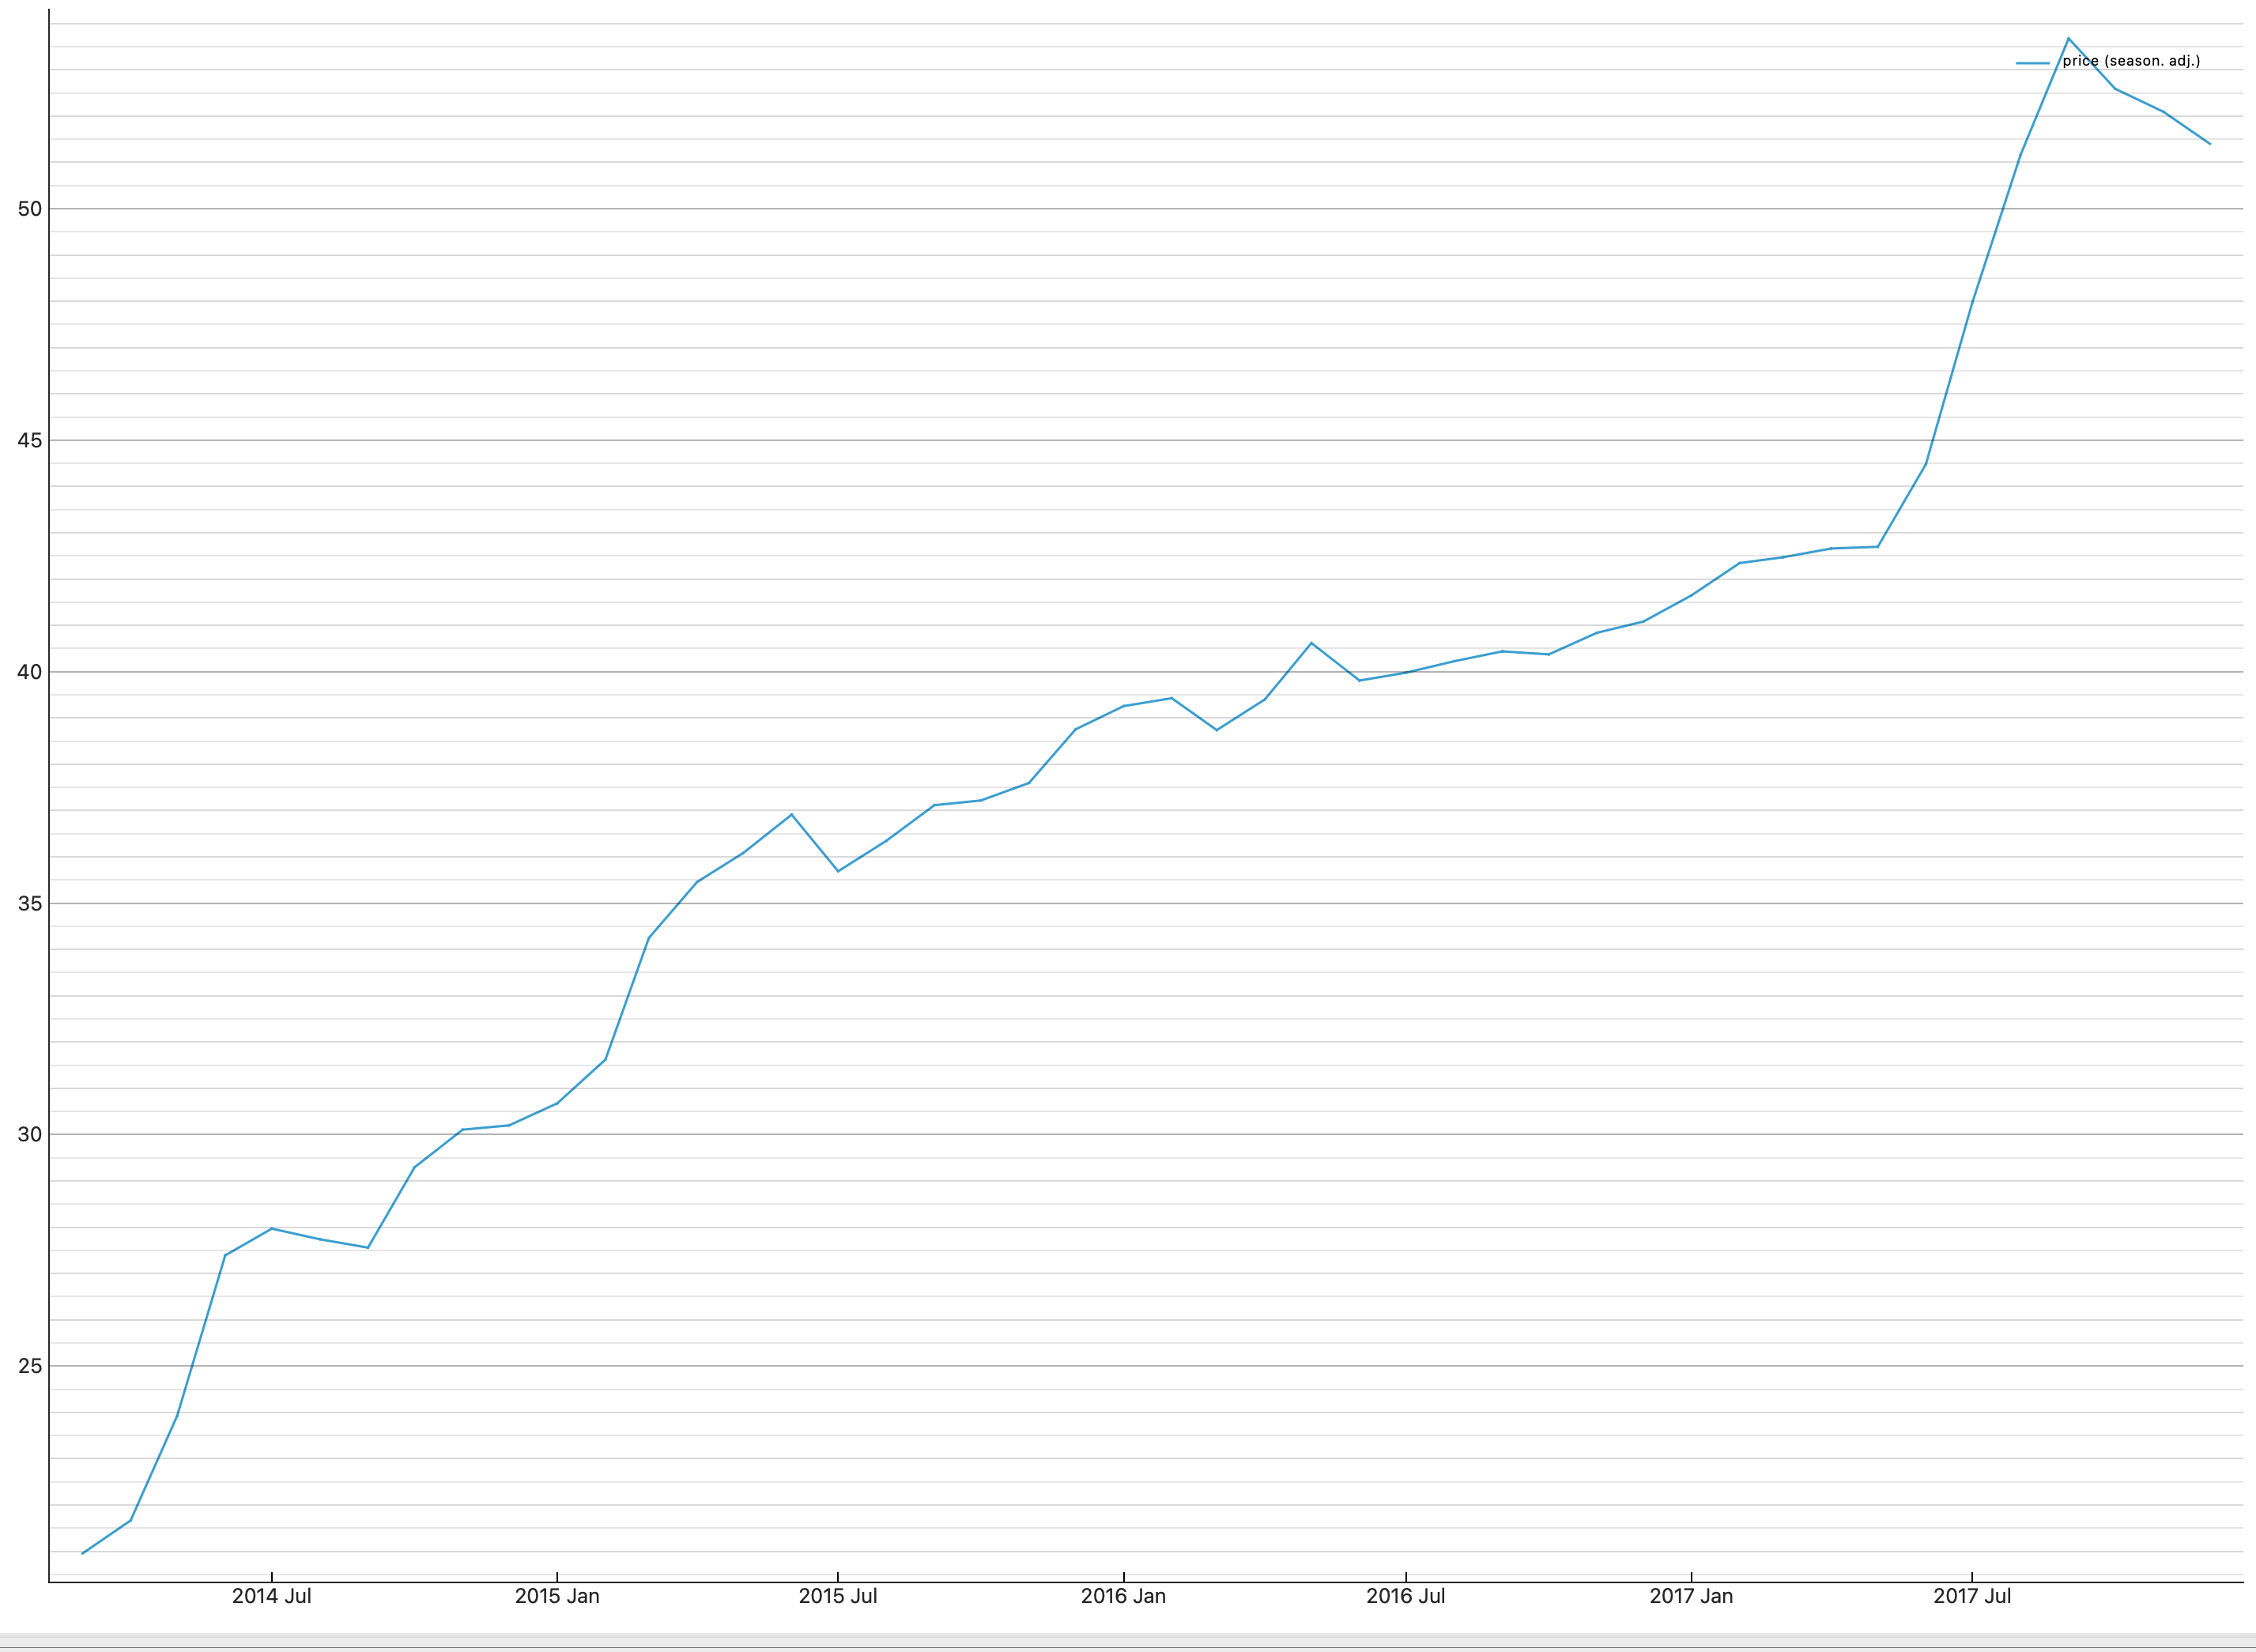

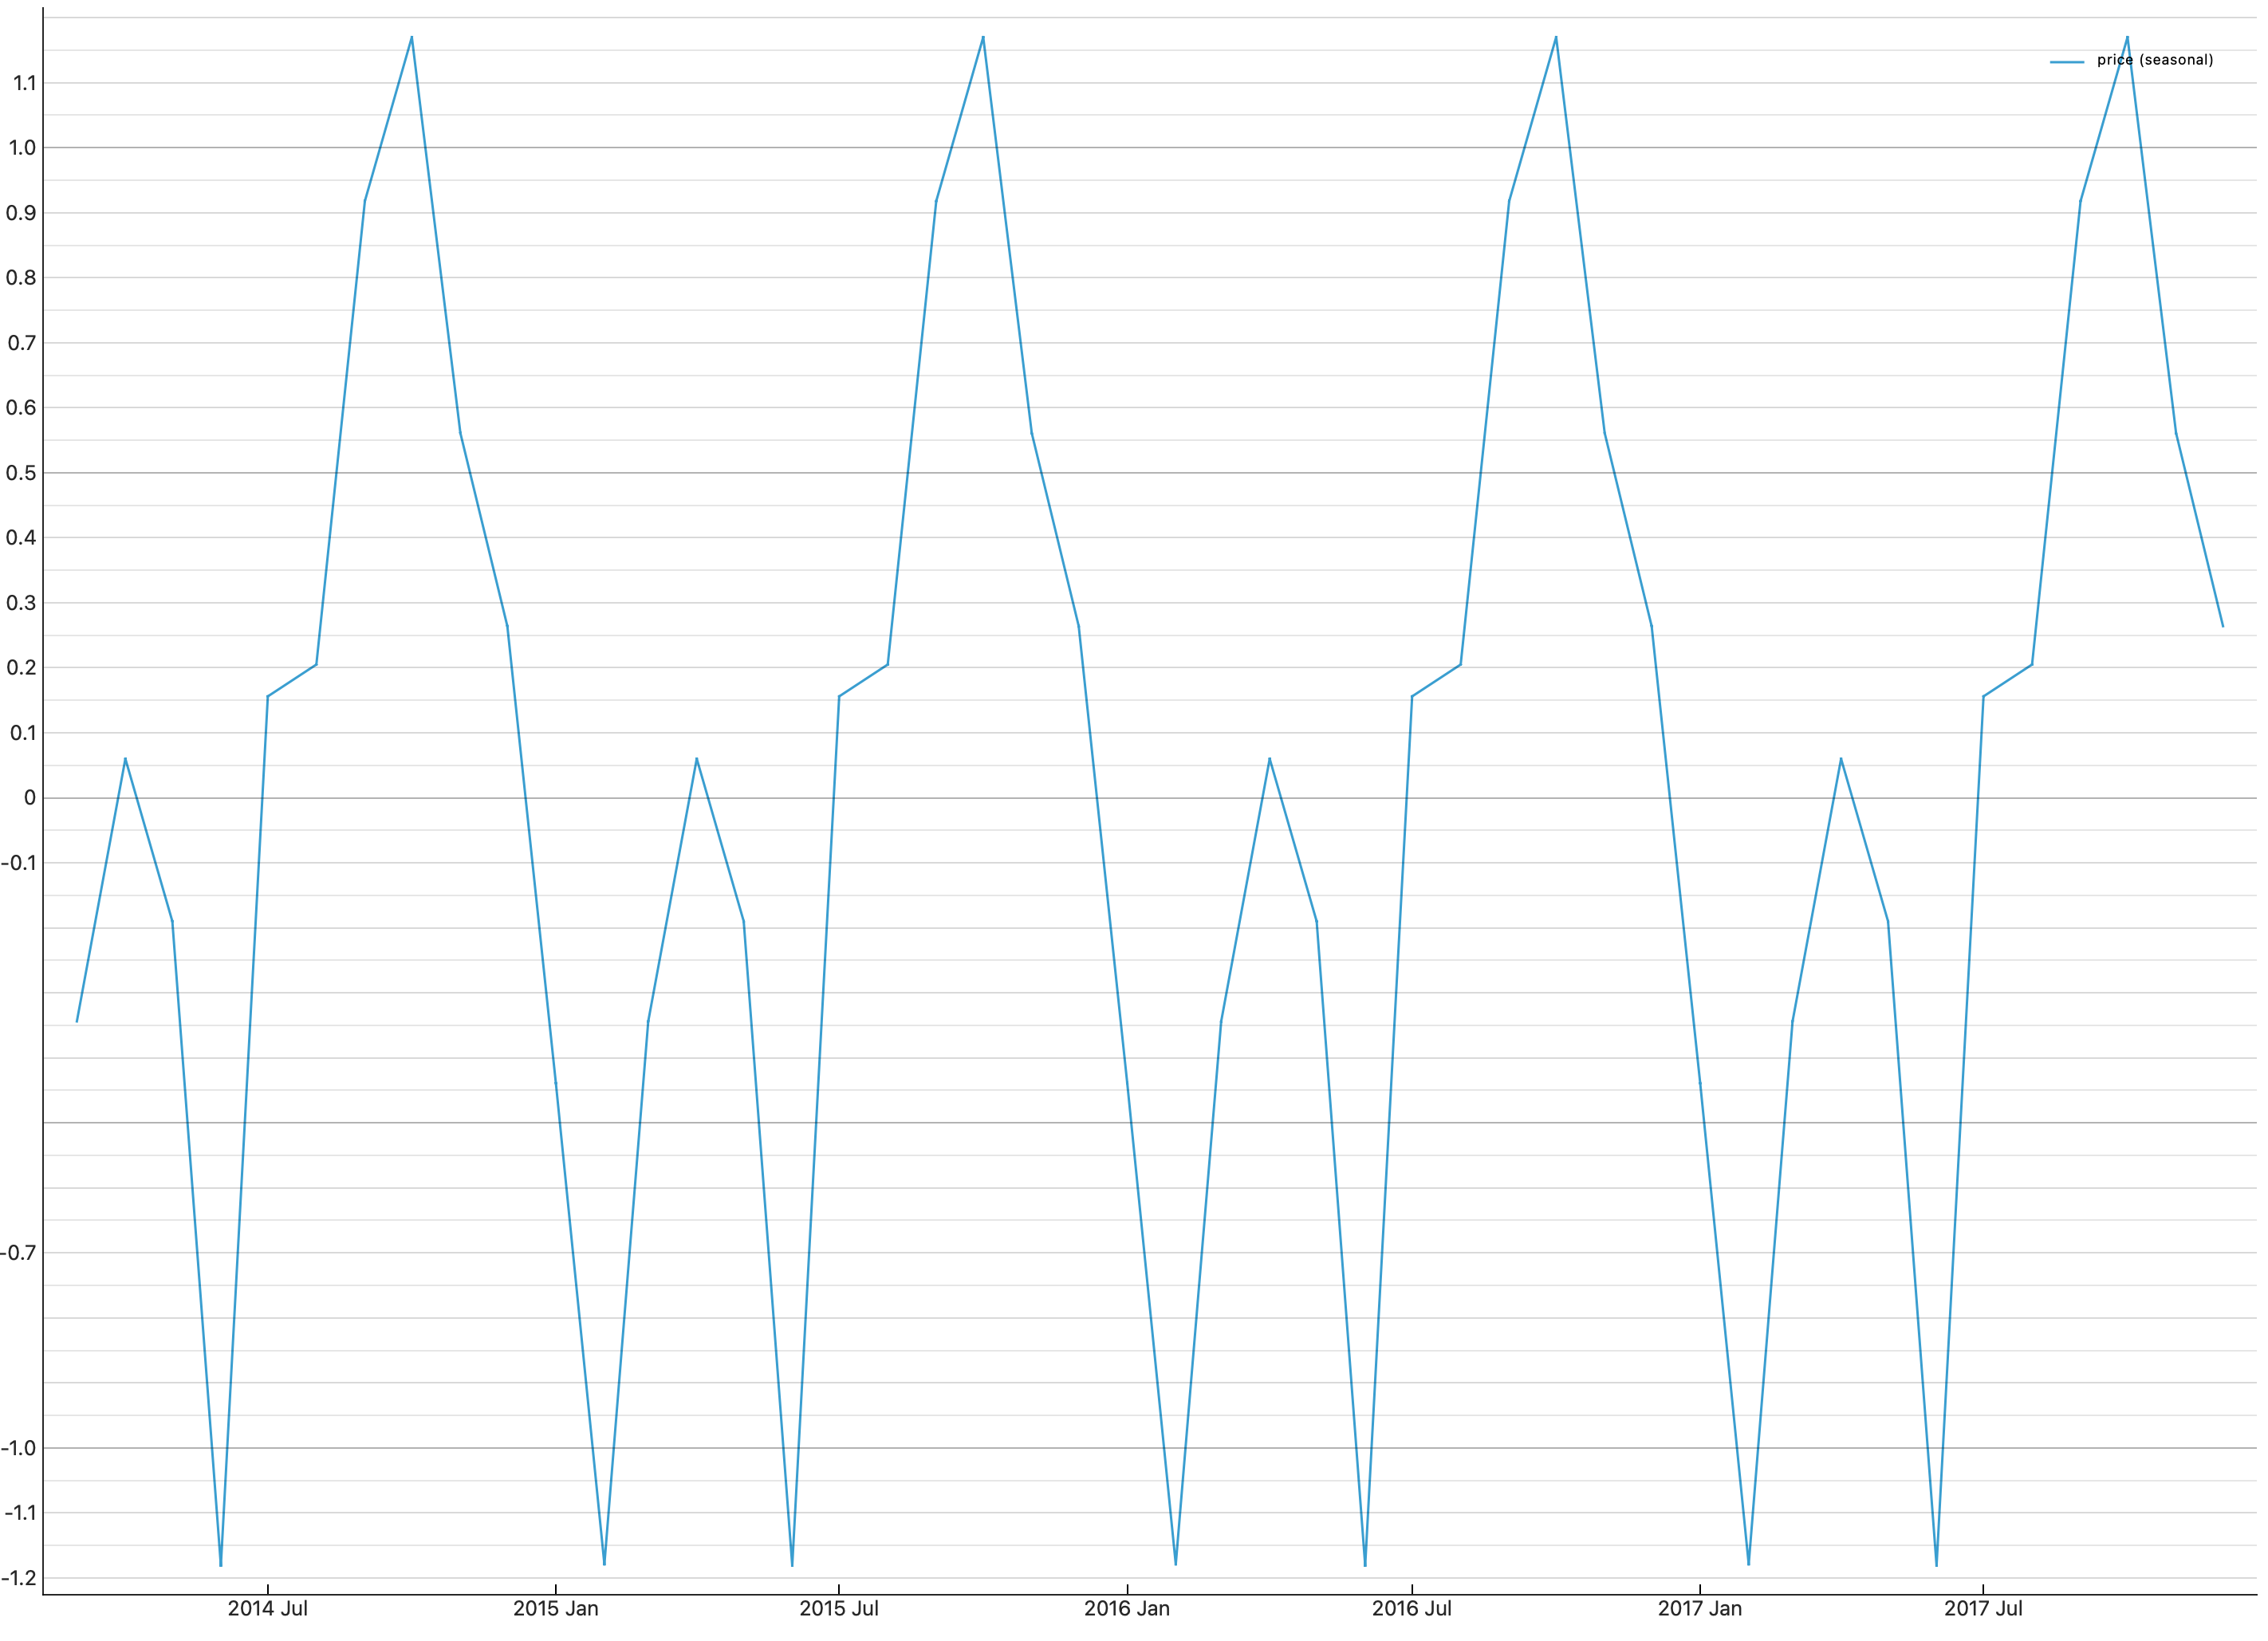

**Висновок до завдання 12:**

Для різниць результат однаковий в обох варіантах: значущий лише лаг 1. Для рівня картина залежить від типу межі. Значення ACF на лагах 1–3 (0.90, 0.78, 0.67) значущі в будь-якому варіанті. Лаг 4 (0.57) значущий лише за сталою межею, а за межею Бартлетта вже ні.

Сезонно скоригований ряд чітко відображає довгостроковий тренд зростання цін, повністю очищений від впливу регулярних часових факторів. Натомість графік сезонної компоненти виділяє виключно циклічні зміни, підтверджуючи наявність чітких, стабільних коливань із визначеною амплітудою на тлі загального подорожчання.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

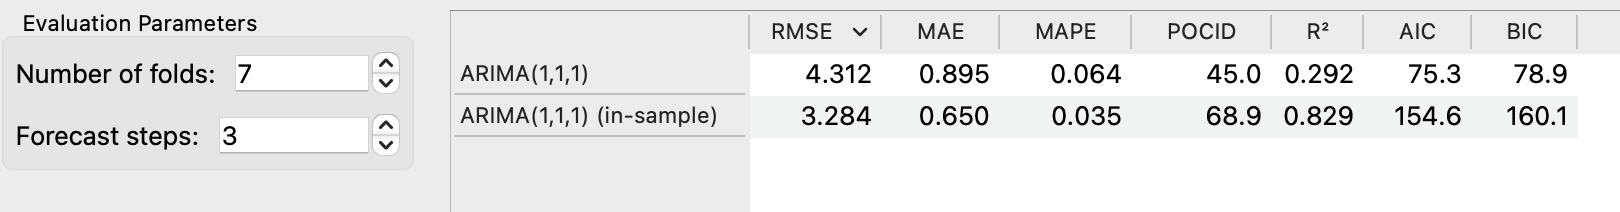

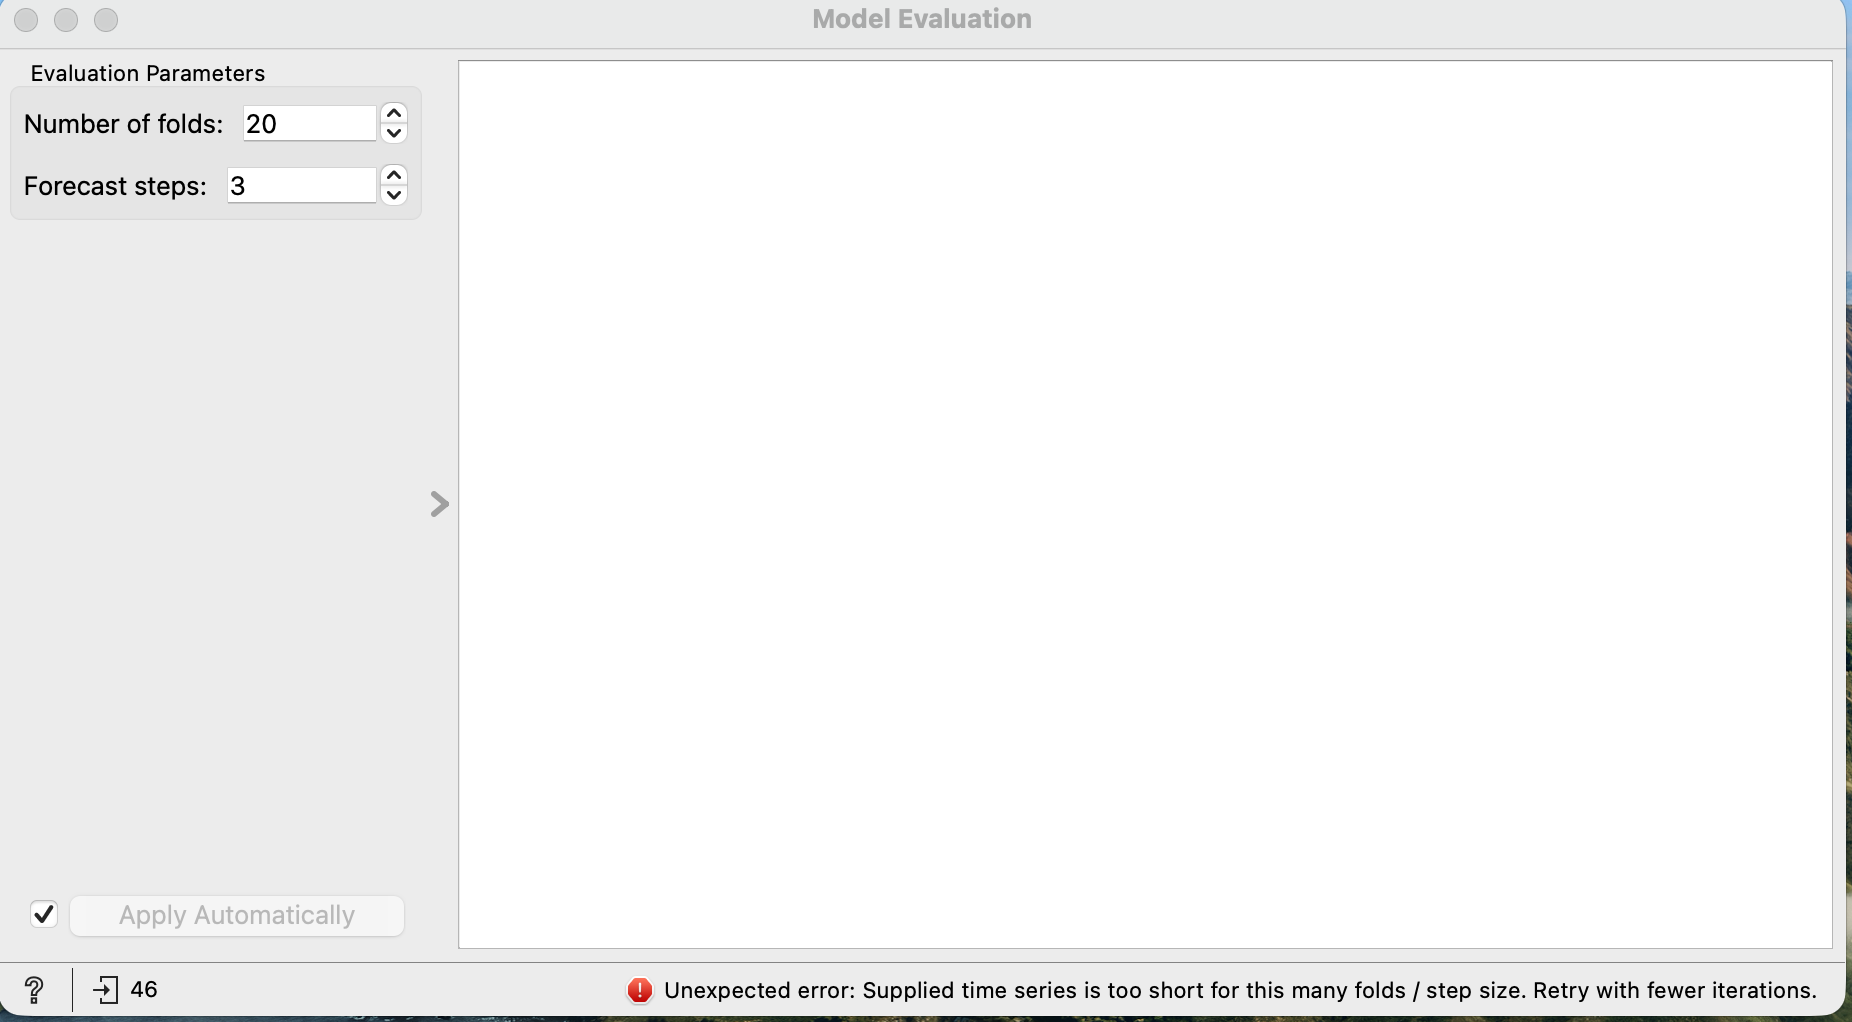

**Висновок до завдання 13:**

Оцінювання моделі $ARIMA(1,1,1)$ продемонструвало задовільну точність прогнозування: на крос-валідації середня абсолютна помилка (MAE) становить $0.895$, а середня абсолютна помилка у відсотках (MAPE) — лише $6.4\%$[cite: 6]. Навчання на всій вибірці (in-sample) очікувано показує вищу точність ($R^2 = 0.829$, $MAPE = 3.5\%$), що підтверджує здатність моделі добре описувати загальну структуру часового ряду[cite: 6].

Наслідки типових налаштувань ($20 \text{ фолдів} \times 3 \text{ кроки}$)
При встановленні типових налаштувань Orange видає повідомлення про помилку: *«Data set is too short for the specified number of folds and forecast steps»*. Це пояснюється тим, що для проведення $20$ фолдів по $3$ кроки тестова вибірка вимагає щонайменше $60$ точок, а з урахуванням необхідної довжини навчального вікна загальний ряд має містити понад $70\text{--}75$ спостережень, чого недостатньо в наявних даних.

Orange здійснює перевірку на останніх $21$ точках ряду за допомогою методу розширюваного вікна (Expanding Window). На першому фолді модель навчається на відрізку від $1$-ї до $(N-21)$-ї точки та прогнозує наступні $3$ спостереження, після чого на кожному наступному кроці навчальна вибірка послідовно збільшується на $3$ точки, аж поки $7$-й фолд не зпрогнозує самі кінцеві значення ряду.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [51]:
# Завдання 14. Відтворення метрик Orange у Python
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

y = series_full['ціна'].values
n = len(y)

num_folds = 7
horizon = 3
train_size_first = n - num_folds * horizon

fold_true, fold_pred = [], []
for fold in range(num_folds):
    train_end = train_size_first + fold * horizon
    y_tr, y_te = y[:train_end], y[train_end:train_end + horizon]
    model = ARIMA(y_tr, order=(1, 1, 1)).fit()
    fold_true.append(y_te)
    fold_pred.append(model.forecast(steps=horizon))

y_true = np.concatenate(fold_true[::-1])
y_pred = np.concatenate(fold_pred[::-1])
error = y_true - y_pred

rmse_py = np.sqrt(np.sum(error ** 2) / len(y_pred))
mae_py = np.median(np.abs(error))
mape_py = np.mean(np.abs(error)) / np.abs(y_true).mean()
pocid_py = 100 * np.mean((np.diff(y_true) * np.diff(y_pred)) > 0)

orange = {'RMSE': 4.312, 'MAE': 0.895, 'MAPE': 0.064, 'POCID': 45.0}
python = {'RMSE': rmse_py, 'MAE': mae_py, 'MAPE': mape_py, 'POCID': pocid_py}

results = pd.DataFrame({
    'Метрика': list(orange),
    'Orange': list(orange.values()),
    'Python': [python[k] for k in orange],
})
results['Збіг до 3 знаків'] = results['Orange'].round(3) == results['Python'].round(3)

print('Порівняння метрик Orange та Python для ARIMA(1,1,1), 7 фолдів:')
print(results.round(3).to_string(index=False))

Порівняння метрик Orange та Python для ARIMA(1,1,1), 7 фолдів:
Метрика  Orange  Python  Збіг до 3 знаків
   RMSE   4.312   4.312              True
    MAE   0.895   0.895              True
   MAPE   0.064   0.064              True
  POCID  45.000  45.000              True


**Висновок до завдання 14:**

Ретроспективна перевірка на 7 фолдах по 3 кроки дала такі результати: наївний прогноз має MAE 2.04 грн, RMSE 3.45 грн, MAPE 4.22%; сезонний наївний має 5.55, 6.62 і 11.88%; середнє має 9.72, 10.51 і 21.29%; дрейф має 2.14, 3.22 і 4.44%. Найкращих результатів за MAE і MAPE досяг наївний прогноз, а за RMSE — дрейф. Тому однозначного переможця немає, і вибір залежить від того, які помилки для нас важливіші. Дрейф краще переносить великі промахи, а наївний прогноз стабільніший на типових місяцях. Для рішень про закупівлю я б обрав дрейф, бо великі помилки в цінах тут коштують більше.

Такий результат пояснюється властивостями ряду. Сила тренду становить $F_T = 0.99$, тобто ціна майже весь час зростає, тому дрейф має враховувати цей нахил. Але за три місяці накопичується лише невеликий приріст, тож різниця між наївним прогнозом і дрейфом невелика. Сезонний наївний прогноз показав найгірший результат, хоча сила сезонності $F_S = 0.76$ висока. Причина в тому, що він бере значення на 12 місяців раніше, а за цей час ціна вже суттєво зросла, тому сезонний зсув не компенсує тренд. Середнє найгірше, бо воно не реагує на зростання і систематично занижує прогноз.

У розбитті 75/25 похибки виявилися значно більшими. Наївний прогноз має MAE 5.81 грн, тобто у 2.85 раза більше, ніж у ретроспективній перевірці, а дрейф — 3.04 грн, тобто у 1.43 раза більше. Різниця пояснюється горизонтом: одноразовий прогноз на 12 місяців уперед накопичує помилку, а прогноз на 3 місяці — ні. Наївний прогноз відчутно страждає від цього, бо він не враховує тренд, а дрейф його враховує. Тому для оцінки якості прогнозу рекомендую ретроспективну перевірку з рухомим початком: вона вимірює точність саме на тому горизонті, на якому ми будемо прогнозувати, а одноразове розбиття 75/25 радше показує, як модель працює на далекому горизонті.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [52]:
# Завдання 15. Матриця напрямку зміни
true_dir = np.diff(y_true) > 0
pred_dir = np.diff(y_pred) > 0

tp_up   = np.sum( true_dir &  pred_dir)
fn_up   = np.sum( true_dir & ~pred_dir)
fp_down = np.sum(~true_dir &  pred_dir)
tn_down = np.sum(~true_dir & ~pred_dir)

conf = pd.DataFrame(
    [[tp_up, fn_up], [fp_down, tn_down]],
    index=['Факт: зросла', 'Факт: впала'],
    columns=['Прогноз: зросла', 'Прогноз: впала'],
)
print(conf)

accuracy = (tp_up + tn_down) / conf.values.sum() * 100
print(f'Частка правильних напрямків: {accuracy:.1f}%  (POCID з Orange: 45.0%)')

              Прогноз: зросла  Прогноз: впала
Факт: зросла                4               3
Факт: впала                 8               5
Частка правильних напрямків: 45.0%  (POCID з Orange: 45.0%)


**Висновок до завдання 15:**

Матриця напрямку зміни для ARIMA(1,1,1) на 7 фолдах: з 20 переходів модель правильно передбачила напрямок у 9, тобто 45%. Це збігається зі значенням POCID з Orange (45.0%). Переходи з нульовою зміною ціни Orange і POCID зараховують як промахи, тому знаменник дорівнює 20, а не 18.

Модель частіше прогнозує зростання: 12 разів із 20, тоді як ціна насправді зростала лише 9 разів. Тобто вона має систематичний нахил до прогнозу зростання, а не просто помиляється навмання. Точність 45% нижча за 50%, яку дав би випадковий вибір напрямку, тому для рішення «купувати зараз чи чекати» модель ненадійна.

Це інше питання, ніж те, на яке відповідають MAE та RMSE. Вони показують, наскільки далеко прогноз від фактичної ціни, тобто розмір похибки. POCID показує, чи правильно модель визначає, куди піде ціна. Модель може мати невелику середню похибку і водночас помилятися в напрямку, а для вибору моменту покупки важливий саме напрямок.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?


Сезонність у ряді є: сила сезонності $F_S = 0.76$ перевищує поріг 0.6, а сила тренду $F_T = 0.99$ показує, що зростання домінує. Для STL-розкладання з періодом 12 це означає, що сезонна складова пояснює суттєву частку коливань ціни, але тренд пояснює ще більше.

Найкращим за MAE (2.04 грн) і MAPE (4.22%) виявився наївний прогноз, а за RMSE (3.22 грн) — дрейф, тож однозначного переможця немає. Обидва базиси перевершили сезонний наївний прогноз і середнє, а ARIMA(1,1,1) на тих самих фолдах дав RMSE 4.31, тобто гірше за дрейф.

Точку зміни режиму я знайшов сканувуванням у завданні 8, але її зовнішнє пояснення має бути з мого висновку до цього завдання, тому тут його варто перенести безпосередньо з тексту завдання 8.

Однакові назви метрик дають різні числа, бо Orange визначає їх інакше: «MAE» там є медіаною абсолютних похибок, «MAPE» — відношенням MAE до середнього значення ціни, а POCID рахує переходи з нульовою зміною як промахи. RMSE збіглася, бо її формула однозначна.

Через 46 спостережень ми не можемо надійно оцінити сезонність: за 4 роки кожен місяць має лише 4 значення, тому сезонний профіль має велику похибку. Тест на точку зміни режиму і тести стаціонарності мають малу потужність, а 7 фолдів по 3 кроки дають лише 21 тестову точку, тож різниця між наївним прогнозом і дрейфом може бути випадковою.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Gemini (Pro 3.1)|
| Для яких саме завдань | Я використовув штучний інтелект для виконання задач 1 - 15, для пояснення завдань, невідомої термінології. Також консультувався стосовно того як користуватися програмою Orange для аналізу|
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Генерував код необхідний для виконання завдань 1 - 15, а також текст для висновків у завданнях.|
| Що ви змінили у згенерованому результаті й чому | Код і тексти висновків, які пропонував ШІ, я перевіряв і змінював. Зокрема переписав комірку завдання 14, бо спочатку MAE і MAPE рахувалися як середнє, а Orange використовує медіану та нормування на середнє значення, тому я привів формули у відповідність до functions.py|
| Що з отриманого ви **перевірили самостійно** і яким способом | Формули метрик я звірив із вихідним кодом Orange3-Timeseries (functions.py). Числа з таблиць перевіряв, порівнюючи їх із виводом своїх комірок і зі скріншотами Orange. Частку правильних напрямків (45%) перерахував з матриці 2×2 і порівняв з POCID.|
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так. Спочатку код для MAE і MAPE рахував середнє замість медіани та нормування, через що розбіжність із Orange виглядала як помилка методу. Також матриця напрямку в першій версії неправильно зараховувала нульові зміни ціни як «впала». Обидві помилки я виправив після перевірки. Також давав неправильні вказівки щодо користування програмою Orange.|

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Фарина А.П. Дата: 21.10.2026